# Time-dependent calibration

Run the functions cell once, then the calls for the observation you want. The notebook is self-contained; it does not import a separate local Python file.

Each observation uses the same three files in `solutions/OBS_ID/`:
- `measurements.npz`
- `SBOBS_ID_all_beam_source_peaks_bins*.npz` (with the beam-centre coordinates added)
- `SBOBS_ID_pointing_angles.npz`

Figures are saved in `plots/OBS_ID/`. Data are loaded once per observation.

Beam numbers start at 0. Antenna numbers start at 1: `antenna=4` means AK04. 

In [19]:
from pathlib import Path

import astropy.units as u
import matplotlib.pyplot as plt
import numpy as np
from astropy.coordinates import SkyCoord
from matplotlib.cm import ScalarMappable
from matplotlib.collections import LineCollection
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator


BEAM_ROWS = [(35, 34, 33, 32, 31, 30), (29, 28, 27, 26, 25, 24), (23, 22, 21, 20, 19, 18), (17, 16, 15, 14, 13, 12), (11, 10, 9, 8, 7, 6), (5, 4, 3, 2, 1, 0)]


def beam_axes(figsize=(17, 12), sharex=False, sharey=False):
    """Create the same staggered beam arrangement for every per-beam figure."""

    fig = plt.figure(figsize=figsize)
    grid = fig.add_gridspec(6, 13)
    axes, shared = {}, None

    for row, beams in enumerate(BEAM_ROWS):
        for col, beam in enumerate(beams):
            left = 2 * col + row % 2
            ax = fig.add_subplot(grid[row, left:left + 2], sharex=shared if sharex else None, sharey=shared if sharey else None)

            if shared is None:
                shared = ax

            ax.tick_params(axis="x", labelbottom=not sharex or row == 5)
            ax.tick_params(axis="y", labelleft=not sharey or col == 0)
            axes[beam] = ax

    return fig, axes


def load_time_data(obs_id, base=None):
    """Read the three saved NPZ files once and align their time origins."""

    obs_id = str(obs_id)
    base = Path(base).expanduser() if base is not None else Path.home() / "Documents/Australia/CSIRO/time_dep"
    folder = base / "solutions" / obs_id

    paths = [p for p in folder.glob(f"SB{obs_id}_all_beam_source_peaks_bins*.npz") if not p.name.endswith(".tmp.npz")]

    if not paths:
        raise FileNotFoundError(f"No all-source NPZ file in {folder}")

    source_file = max(paths, key=lambda p: p.stat().st_mtime)
    loaded = []

    for path in (folder / "measurements.npz", source_file, folder / f"SB{obs_id}_pointing_angles.npz"):
        with np.load(path, allow_pickle=False) as archive:
            loaded.append({key: archive[key] for key in archive.files})

    measurements, sources, angles = loaded

    origin = float(np.nanmedian((measurements["bin_start_mjd_seconds"] + measurements["bin_end_mjd_seconds"]) / 2 - measurements["hours"] * 3600))
    order = np.argsort(measurements["hours"])
    source_order = np.argsort(sources["hours"])
    hours = measurements["hours"][order]
    angle_hours = (angles["raw_elapsed_seconds"] + float(angles["observation_start_mjd_seconds"]) - origin) / 3600
    source_offset = (float(sources["observation_start_mjd_seconds"]) - origin) / 3600
    roll_times, elevation_times, azimuth_crossings, antenna_rows = [], [], [], []

    for antenna in np.unique(angles["raw_antenna_ids"]):
        rows = np.flatnonzero(angles["raw_antenna_ids"] == antenna)
        rows = rows[np.argsort(angle_hours[rows])]
        antenna_rows.append(rows)

        t = angle_hours[rows]
        usable = angles["raw_tracking"][rows].astype(bool) & np.isfinite(t)

        dt = np.diff(t)
        positive = dt[dt > 0]

        if not positive.size:
            continue

        adjacent = usable[:-1] & usable[1:] & (dt > 0) & (dt <= 3 * np.median(positive))

        roll = angles["raw_polangle"][rows]
        candidates = np.flatnonzero(adjacent & np.isfinite(roll[:-1]) & np.isfinite(roll[1:]))

        if candidates.size:
            i = candidates[np.argmax(np.abs(np.diff(roll)[candidates] / dt[candidates]))]
            roll_times.append((t[i] + t[i + 1]) / 2)

        elevation = angles["raw_elevation"][rows]
        selected = np.flatnonzero(usable & np.isfinite(elevation))

        if selected.size:
            elevation_times.append(t[selected[np.argmax(elevation[selected])]])

        azimuth = angles["raw_azimuth"][rows]
        sign_change = ((azimuth[:-1] < 0) & (azimuth[1:] >= 0)) | ((azimuth[:-1] > 0) & (azimuth[1:] <= 0))
        candidates = np.flatnonzero(adjacent & np.isfinite(azimuth[:-1]) & np.isfinite(azimuth[1:]) & sign_change)

        if candidates.size:
            azimuth_crossings.append((t[candidates] + t[candidates + 1]) / 2)

    if not roll_times:
        raise ValueError("No usable tracked POLANGLE changes found.")

    rotation_hour = float(np.median(roll_times))

    plot_dir = base / "plots" / obs_id
    plot_dir.mkdir(parents=True, exist_ok=True)

    result = dict(obs_id=obs_id, plot_dir=plot_dir, measurements=measurements, sources=sources, angles=angles, order=order, hours=hours, source_offset=source_offset, source_hours=sources["hours"][source_order] + source_offset, source_bins=sources["bin_numbers"][source_order], source_flux=sources["peak_mjy_beam"][source_order], source_order=source_order, angle_hours=angle_hours, antenna_rows=antenna_rows, rotation_hour=rotation_hour)
    result["elevation_hour"] = float(np.median(elevation_times)) if elevation_times else None
    result["azimuth_hour"] = float(np.median([times[np.argmin(np.abs(times - rotation_hour))] for times in azimuth_crossings])) if azimuth_crossings else None

    source_branch = str(sources.get("branch", "unspecified"))
    print(f"SB{obs_id}: {len(hours)} measurement bins; {len(source_order)} source bins ({source_branch} calibration); rotation marker {rotation_hour:.4f} h")

    return result


def plot_bandpass(data, beam=None, antenna=None, ratio=False, ylim=None, fontsize = 14):
    """Plot all solutions, one beam, one antenna, or one beam/antenna. Antenna=4 means AK04."""
    plt.rcParams.update({"font.size": fontsize})

    m = data["measurements"]
    hours = data["hours"]
    values = m["snapshot_bandpass"][data["order"]]
    reference = m["full_bandpass"]
    values = values[..., 2:3] if ratio else values[..., :2]
    reference = reference[..., 2:3] if ratio else reference[..., :2]
    _, n_beams, n_antennas, _ = values.shape

    if beam is not None and not 0 <= beam < n_beams:
        raise ValueError(f"Choose beam 0–{n_beams - 1}.")

    if antenna is not None and not 1 <= antenna <= n_antennas:
        raise ValueError(f"Choose antenna 1–{n_antennas} (AK numbers).")

    bs = slice(None) if beam is None else slice(beam, beam + 1)
    ants = slice(None) if antenna is None else slice(antenna - 1, antenna)

    if ylim is None:
        finite = np.concatenate((values[:, bs, ants].ravel(), reference[bs, ants].ravel(), [1.0] if ratio else []))
        finite = finite[np.isfinite(finite)]

        if not finite.size:
            raise ValueError("No finite bandpass values for this selection.")

        low, high = finite.min(), finite.max()
        padding = 0.05 * (high - low) if high > low else 0.01
        low, high = low - padding, high + padding
    else:
        low, high = ylim

    if not low < high:
        raise ValueError("ylim must have increasing limits.")

    span = high - low
    t_min, t_max = hours.min(), hours.max()
    t_span = max(t_max - t_min, 1e-9)
    rotation_hour = data["rotation_hour"]

    colors = ("C0",) if ratio else ("C0", "C1")
    dashes = ("--",) if ratio else ((0, (2, 2)), (0, (6, 3)))
    names = ("X/Y",) if ratio else ("X", "Y")
    ylabel = "Median X / median Y" if ratio else "Median bandpass amplitude"

    legend = [Line2D([], [], color=color, label=f"Snapshot {name}") for color, name in zip(colors, names)]
    if not ratio:
        legend += [Line2D([], [], color=color, linestyle=dash, label=f"Full observation {name}") for color, dash, name in zip(colors, dashes, names)]

    legend.append(Line2D([], [], color="black", label=f"Highest elevation"))

    if beam is None and antenna is None:
        fig, ax = plt.subplots(figsize=(max(8, n_beams * 0.9), max(6, n_antennas * 0.72)))

        grid = [[(x, 0), (x, n_antennas)] for x in range(n_beams + 1)]
        grid += [[(0, y), (n_beams, y)] for y in range(n_antennas + 1)]
        ax.add_collection(LineCollection(grid, colors="0.35", linewidths=0.4))

        time_x = 0.06 + 0.88 * (hours - t_min) / t_span
        rotation_x = 0.06 + 0.88 * (rotation_hour - t_min) / t_span
        vertical = [[(b + rotation_x, row + 0.06), (b + rotation_x, row + 0.94)] for b in range(n_beams) for row in range(n_antennas)]
        ax.add_collection(LineCollection(vertical, colors="black", linewidths=0.7, alpha=0.7, zorder=1.5))

        for pol, (color, dash) in enumerate(zip(colors, dashes)):
            traces, references = [], []

            for b in range(n_beams):
                x = b + time_x

                for ant in range(n_antennas):
                    bottom = n_antennas - 1 - ant + 0.06
                    trace = values[:, b, ant, pol]
                    trace = np.where((trace >= low) & (trace <= high), trace, np.nan)
                    traces.append(np.column_stack((x, bottom + 0.88 * (trace - low) / span)))

                    ref = reference[b, ant, pol]

                    if np.isfinite(ref) and low <= ref <= high:
                        y = bottom + 0.88 * (ref - low) / span
                        references.append([(x[0], y), (x[-1], y)])

            if not ratio:
                ax.add_collection(LineCollection(references, colors=color, linestyles=dash, linewidths=0.6, zorder=1))
            ax.add_collection(LineCollection(traces, colors=color, linewidths=0.8, zorder=2))

        ax.set_xlim(0, n_beams)
        ax.set_ylim(0, n_antennas)
        ax.set_xticks(np.arange(n_beams) + 0.5, [f"B{b:02d}" for b in range(n_beams)])
        ax.set_yticks(n_antennas - 0.5 - np.arange(n_antennas), [f"AK{ant + 1:02d}" for ant in range(n_antennas)])
        ax.xaxis.tick_top()
        ax.tick_params(length=0, labelsize=9)
        ax.set_xlabel(f"Hours from observation start ({t_min:g} to {t_max:g} h per panel)")
        ax.set_ylabel(f"{ylabel} ({low:.3f} to {high:.3f} per panel)")

        suffix, selection = "all_beams_all_antennas", ""
        fig.subplots_adjust(left=0.055, right=0.995, bottom=0.04, top=0.94)

    else:
        if beam is None:
            fig, axes = beam_axes(sharex=True, sharey=True)
            panels = [(b, antenna - 1, ax) for b, ax in axes.items() if b < n_beams]

            for b, ax in axes.items():
                if b >= n_beams:
                    ax.set_visible(False)

            suffix, selection = f"AK{antenna:02d}_all_beams", f" · AK{antenna:02d}"

        else:
            ids = list(range(n_antennas)) if antenna is None else [antenna - 1]
            columns = min(6, len(ids))
            rows = (len(ids) + columns - 1) // columns

            fig, axes = plt.subplots(rows, columns, sharex=True, sharey=True, figsize=(max(8, 2.8 * columns), max(4, 2 * rows)), squeeze=False)
            panels = [(beam, ant, ax) for ant, ax in zip(ids, axes.flat)]

            for ax in list(axes.flat)[len(ids):]:
                ax.set_visible(False)

            suffix = f"beam{beam:02d}_" + ("all_antennas" if antenna is None else f"AK{antenna:02d}")
            selection = f" · Beam {beam:02d}" + ("" if antenna is None else f" · AK{antenna:02d}")

        for b, ant, ax in panels:
            ax.axvline(rotation_hour, color="black", linewidth=0.8, zorder=1)

            for pol, (color, dash) in enumerate(zip(colors, dashes)):
                if not ratio:
                    ax.axhline(reference[b, ant, pol], color=color, linestyle=dash, linewidth=0.8, zorder=1)
                ax.plot(hours, values[:, b, ant, pol], color=color, linewidth=1, zorder=2)

            ax.set_title(f"Beam {b:02d}" if beam is None else f"AK{ant + 1:02d}", fontsize=fontsize)
            ax.tick_params(labelsize=fontsize)
            ax.set_ylim(low, high)

        fig.supxlabel("Hours from observation start")
        fig.supylabel(ylabel)
        fig.subplots_adjust(left=0.07, right=0.99, bottom=0.07, top=0.87, wspace=0.20, hspace=0.40)

    quantity = "X_over_Y" if ratio else "amplitude"
    fig.suptitle(f"SB{data['obs_id']}{selection} · Bandpass {'X/Y' if ratio else 'amplitudes'} versus time", y=0.985)
    fig.legend(handles=legend, loc="upper center", bbox_to_anchor=(0.5, 0.97), ncol=len(legend), frameon=False)

    fig.savefig(data["plot_dir"] / f"SB{data['obs_id']}_bandpass_{quantity}_{suffix}.pdf", bbox_inches='tight')

    plt.show()
    plt.close(fig)


def plot_time_metric(data, metric="flux_scale", stokes="Q", plot=False, branch="before", fontsize = 14):
    """Print statistics and optionally plot before or after calibration."""
    plt.rcParams.update({"font.size": fontsize})
    options = {
        "flux_scale": ("median_flux_ratio", 1, "Median Selavy / RACS-low3 integrated flux ratio", "Flux scale", "dimensionless"),
        "rms": ("rms_mjy_beam", 1000, r"RMS ($\mu$Jy/beam)", "RMS", "µJy/beam"),
        "ra": ("median_ra_arcsec", 1, "Median RA offset (arcsec)", "RA offset", "arcsec"),
        "dec": ("median_dec_arcsec", 1, "Median Dec offset (arcsec)", "Dec offset", "arcsec"),
        "leakage": ("leakage_percent", 1, f"Fitted I → {stokes} leakage (%)", f"Stokes {stokes} leakage", "%"),
    }
    key, factor, ylabel, title, unit = options[metric]

    m = data["measurements"]
    column = m["branches"].astype(str).tolist().index(branch)
    values = factor * m[f"snapshot_{key}"][data["order"], column]

    if metric == "leakage":
        values = values[:, ("Q", "U", "V").index(stokes)]

    finite = values[np.isfinite(values)]

    print(f"\nSB{data['obs_id']} · {title} · {branch} ({unit})")

    if finite.size:
        print(f"Median: {np.median(finite):.4f}")
        print(f"Min:    {finite.min():.4f}")
        print(f"Max:    {finite.max():.4f}")
        print(f"Std:    {np.std(finite):.4f}")
    else:
        print("No finite measurements.")

    if plot:
        fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
        ax.axvline(data["rotation_hour"], color="black", linewidth=1, alpha=0.7, label=f"Higest elevation")
        ax.plot(data["hours"], values, "o-", color="C0", label="15-min snapshots")

        if metric in ("ra", "dec"):
            ax.axhline(0, color="0.5", linestyle="--", linewidth=0.8)

        ax.set_xlabel("Hours from observation start")
        ax.set_ylabel(ylabel)
        ax.set_title(f"SB{data['obs_id']} · {title} · {branch} additional calibration")
        ax.legend()

        suffix = f"leakage_{stokes}" if metric == "leakage" else metric
        fig.savefig(data["plot_dir"] / f"SB{data['obs_id']}_{suffix}_{branch}_vs_time.pdf", bbox_inches='tight')
        plt.show()
        plt.close(fig)



def plot_source_ratios(data, bin_gap=6, last_bin=None, min_flux_mjy=10, vmin=0.9, vmax=1.1, dot_size=35, fontsize = 14):
    """Plot the earliest pair, a pair across rotation, and the latest pair."""
    plt.rcParams.update({"font.size": fontsize})
    s = data["sources"]

    if str(s.get("branch", "before")) != "before":
        raise ValueError("These plots require the before-calibration all-source archive.")

    order = data["source_order"]

    if last_bin is not None:
        order = order[s["bin_numbers"][order] <= last_bin]

    bins = s["bin_numbers"][order]
    flux = s["peak_mjy_beam"][order]

    origin = float(s["observation_start_mjd_seconds"])
    offset = data["source_offset"]
    hours = s["hours"][order] + offset
    starts = (s["bin_start_mjd_seconds"][order] - origin) / 3600 + offset
    ends = (s["bin_end_mjd_seconds"][order] - origin) / 3600 + offset

    centre = data["rotation_hour"]
    by_bin = {int(number): i for i, number in enumerate(bins)}
    available = np.isfinite(flux).any(axis=1)

    candidates = [(i, by_bin[int(number) + bin_gap]) for i, number in enumerate(bins) if int(number) + bin_gap in by_bin]
    candidates = [(i, j) for i, j in candidates if available[i] and available[j]]

    before = [(i, j) for i, j in candidates if ends[i] <= centre and ends[j] <= centre]
    across = [(i, j) for i, j in candidates if ends[i] <= centre and starts[j] >= centre]
    after = [(i, j) for i, j in candidates if starts[i] >= centre and starts[j] >= centre]

    if not before or not across or not after:
        raise ValueError(f"SB{data['obs_id']}: insufficient bins for {bin_gap}-bin comparisons; reduce bin_gap or extend last_bin.")

    rows = [min(before, key=lambda p: hours[p[0]]), min(across, key=lambda p: abs((hours[p[0]] + hours[p[1]]) / 2 - centre)), max(after, key=lambda p: hours[p[1]])]

    ra, dec, beams = s["source_ra_deg"], s["source_dec_deg"], s["source_beam_ids"]
    reference = (s["source_reference_peak_mjy_beam"] >= min_flux_mjy) & np.isfinite(ra) & np.isfinite(dec)

    cmap = LinearSegmentedColormap.from_list("blue_grey_orange", ["#0072B2", "#D9D9D9", "#FFB000"])
    norm = TwoSlopeNorm(vmin=vmin, vcenter=1, vmax=vmax)

    for label, (ib, ia) in zip(("Before jump", "Across jump", "After jump"), rows):
        selected = reference & np.isfinite(flux[ib]) & np.isfinite(flux[ia]) & (flux[ib] > 0) & (flux[ia] > 0)
        ratio = np.full(flux.shape[1], np.nan)
        ratio[selected] = flux[ia, selected] / flux[ib, selected]

        fig, axes = beam_axes(figsize=(19, 16))

        for beam, ax in axes.items():
            keep = selected & (beams == beam)
            ax.set_box_aspect(1)
            ax.set_title(f"Beam {beam:02d}", fontsize=fontsize)

            if keep.any():
                ax.scatter(ra[keep], dec[keep], c=ratio[keep], cmap=cmap, norm=norm, s=dot_size, edgecolors="0.25", linewidths=0.35)
                ax.invert_xaxis()
                ax.set_aspect(1 / np.cos(np.deg2rad(np.median(dec[keep]))), adjustable="datalim")
                ax.ticklabel_format(style="plain", useOffset=False)
                ax.xaxis.set_major_locator(MaxNLocator(3))
                ax.yaxis.set_major_locator(MaxNLocator(3))
            else:
                ax.text(0.5, 0.5, "No valid sources", transform=ax.transAxes, ha="center", va="center", fontsize=fontsize)
                ax.set_xticks([])
                ax.set_yticks([])

            ax.tick_params(axis="both", which="both", labelbottom=False, labeltop=False, labelleft=False, labelright=False)
            ax.set_xticks([])
            ax.set_yticks([])

        fig.suptitle(f"SB{data['obs_id']}", y=0.99, fontsize=fontsize)
        fig.text(0.48, 0.965, f"{label} · bin-{bins[ia]:03d} / bin-{bins[ib]:03d}", ha="center", fontsize=fontsize)
        if selected.any():
            ra_min, ra_max = ra[selected].min(), ra[selected].max()
            dec_min, dec_max = dec[selected].min(), dec[selected].max()

            fig.supxlabel(f"Right ascension [{ra_min:.1f} to {ra_max:.1f} deg]", x=0.48)
            fig.supylabel(f"Declination [{dec_min:.1f} to {dec_max:.1f} deg]")
        fig.subplots_adjust(left=0.055, right=0.90, bottom=0.06, top=0.93, wspace=0.05, hspace=0.15)

        cax = fig.add_axes([0.93, 0.10, 0.015, 0.80])
        fig.colorbar(ScalarMappable(norm=norm, cmap=cmap), cax=cax, label="Peak flux ratio")

        fig.savefig(data["plot_dir"] / f"SB{data['obs_id']}_36beams_ratio_bin{bins[ia]:03d}_over_bin{bins[ib]:03d}.pdf", bbox_inches='tight')

        print(f"{label}: bin-{bins[ia]:03d} / bin-{bins[ib]:03d}")

        plt.show()
        plt.close(fig)

    return [(int(bins[ib]), int(bins[ia])) for ib, ia in rows]


def plot_source_lightcurves(data, min_flux_mjy=10, min_east_west_deg=1.0, north_half_width_deg=0.25, last_bin=None, fontsize = 14):
    """Track the brightest fixed E/W reference sources without a later flux cut."""
    plt.rcParams.update({"font.size": fontsize})

    s = data["sources"]

    if str(s.get("branch", "before")) != "before":
        raise ValueError("These plots require the before-calibration all-source archive.")

    if "beam_centre_ra_deg" not in s or "beam_centre_dec_deg" not in s:
        raise ValueError("Add beam-centre coordinates to the all-source file using the one-time preparation cell.")

    keep_bins = np.ones(len(data["source_bins"]), dtype=bool) if last_bin is None else data["source_bins"] <= last_bin
    hours, bins, flux = data["source_hours"][keep_bins], data["source_bins"][keep_bins], data["source_flux"][keep_bins]

    beams = s["beam_ids"]
    sources = SkyCoord(s["source_ra_deg"] * u.deg, s["source_dec_deg"] * u.deg, frame="icrs")

    centre = data["rotation_hour"]
    before, after = np.flatnonzero(hours < centre), np.flatnonzero(hours >= centre)
    pair = (before[-1], after[0]) if before.size and after.size else None

    if pair is not None and bins[pair[1]] != bins[pair[0]] + 1:
        pair = None

    if pair is None:
        print("No adjacent bins bracket rotation; plotting tracks without a change summary.")
    else:
        print(f"SB{data['obs_id']} · bin-{bins[pair[0]]:03d} → bin-{bins[pair[1]]:03d}")

    print("Change = 100 × (after / before − 1)")
    print("Direction   Sources   Mean (%)   Median (%)")

    result = {}

    for side, color in (("east", "C0"), ("west", "C1")):
        tracks = np.full((len(hours), len(beams)), np.nan)
        selected_sources = np.full(len(beams), -1, dtype=int)

        for j, beam in enumerate(beams):
            beam_centre = SkyCoord(s["beam_centre_ra_deg"][j] * u.deg, s["beam_centre_dec_deg"][j] * u.deg, frame="icrs")
            east, north = beam_centre.spherical_offsets_to(sources)

            selected = (s["source_beam_ids"] == beam) & (s["source_reference_peak_mjy_beam"] >= min_flux_mjy)
            selected &= np.abs(north.deg) <= north_half_width_deg
            selected &= east.deg >= min_east_west_deg if side == "east" else east.deg <= -min_east_west_deg
            candidates = np.flatnonzero(selected)

            if candidates.size:
                source = candidates[np.argmax(s["source_reference_peak_mjy_beam"][candidates])]
                selected_sources[j] = source
                tracks[:, j] = flux[:, source]

        changes = np.array([])

        if pair is not None:
            ib, ia = pair
            valid = np.isfinite(tracks[ib]) & np.isfinite(tracks[ia]) & (tracks[ib] > 0) & (tracks[ia] > 0)
            changes = 100 * (tracks[ia, valid] / tracks[ib, valid] - 1)

        mean = float(np.mean(changes)) if changes.size else np.nan
        median = float(np.median(changes)) if changes.size else np.nan
        print(f"{side.capitalize():<10} {changes.size:>7} {mean:>10.3f} {median:>12.3f}")

        fig, axes = beam_axes(sharex=True)
        beam_index = {int(beam): j for j, beam in enumerate(beams)}

        for beam, ax in axes.items():
            j = beam_index.get(beam)

            ax.axvline(centre, color="black", linewidth=0.9)

            if j is not None and np.isfinite(tracks[:, j]).any():
                ax.plot(hours, tracks[:, j], "o-", color=color, markersize=2.5, linewidth=0.8)
            else:
                ax.text(0.5, 0.5, "No selected source", transform=ax.transAxes, ha="center", va="center", fontsize=fontsize)

            ax.set_title(f"Beam {beam:02d}", fontsize=fontsize)
            ax.tick_params(labelsize=fontsize)
            ax.ticklabel_format(axis="y", style="plain", useOffset=False)

        handles = [Line2D([], [], color=color, marker="o", label=f"{side.capitalize()} source"), Line2D([], [], color="black", label=f"Highest elevation")]

        fig.suptitle(f"SB{data['obs_id']}", y=0.98)
        fig.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, 0.95), ncol=2, frameon=False)
        fig.supxlabel("Hours from observation start")
        fig.supylabel("Peak flux density (mJy/beam)")
        fig.subplots_adjust(left=0.07, right=0.99, bottom=0.06, top=0.89, wspace=0.75, hspace=0.45)

        fig.savefig(data["plot_dir"] / f"SB{data['obs_id']}_{side}_source_lightcurves.pdf", bbox_inches='tight')

        plt.show()
        plt.close(fig)

        result[side] = dict(source_indices=selected_sources, hours=hours, flux=tracks, changes_percent=changes, mean_percent=mean, median_percent=median)

    return result


def plot_pointing_angles(data, fontsize=14):
    """Plot tracked angles with a marker at highest elevation."""

    plt.rcParams.update({"font.size": fontsize})
    angles = data["angles"]
    hours = data["angle_hours"]
    tracking = angles["raw_tracking"].astype(bool)

    peak_hours = []

    for rows in data["antenna_rows"]:
        usable = rows[tracking[rows] & np.isfinite(hours[rows]) & np.isfinite(angles["raw_elevation"][rows])]

        if usable.size:
            peak = usable[np.argmax(angles["raw_elevation"][usable])]
            peak_hours.append(hours[peak])

    if not peak_hours:
        raise ValueError("No usable elevation measurements.")

    peak_hour = float(np.median(peak_hours))

    plots = [("raw_polangle", "POLANGLE"), ("raw_azimuth", "Azimuth"), ("raw_elevation", "Elevation")]
    fig, axes = plt.subplots(1, 3, figsize=(20, 5), layout="constrained")

    for ax, (key, name) in zip(axes, plots):
        for rows in data["antenna_rows"]:
            values = np.where(tracking[rows], angles[key][rows], np.nan)
            ax.plot(hours[rows], values, color="C0", linewidth=0.8, alpha=0.25)

        ax.axvline(peak_hour, color="black", linewidth=1.2, label="Highest elevation")
        ax.set_xlabel("Hours from observation start")
        ax.set_ylabel(f"{name} [deg]")
        ax.legend(frameon=False, loc = 'upper right', fontsize=fontsize)

    fig.savefig(data["plot_dir"] / f"SB{data['obs_id']}_pointing_angles.pdf", bbox_inches="tight")

    plt.show()
    plt.close(fig)


def plot_amplitude_jump(selections, invert=(), normalization = False, fontsize=14, ymin = 0.95, ymax = 1.05):
    """Compare after/before-rotation amplitudes across antennas. invert contains (obs_id, beam) pairs."""

    if not selections:
        raise ValueError("Select at least one observation and beam.")
    plt.rcParams.update({"font.size": fontsize})
    invert = {(str(obs), beam) for obs, beam in invert}
    ratios = {}

    for data, beam in selections:
        hours = data["hours"]
        centre = data["rotation_hour"]
        before = np.flatnonzero(hours < centre)
        after = np.flatnonzero(hours > centre)

        if not before.size or not after.size:
            raise ValueError(f"SB{data['obs_id']}: no snapshots on both sides of rotation.")

        ib, ia = before[-1], after[0]
        m = data["measurements"]
        amp = m["snapshot_bandpass"][data["order"], beam, :, :2]
        valid = np.isfinite(amp[ib]) & np.isfinite(amp[ia]) & (amp[ib] != 0)
        ratio = np.divide(amp[ia], amp[ib], out=np.full(amp[ib].shape, np.nan), where=valid)
        key = (str(data["obs_id"]), beam)

        if key in invert:
            ratio = np.divide(1, ratio, out=np.full(ratio.shape, np.nan), where=np.isfinite(ratio) & (ratio != 0))

        if normalization:
            for pol in range(2):
                values = ratio[:, pol]
                finite = np.isfinite(values)

                if finite.any():
                    low, high = values[finite].min(), values[finite].max()
                    ratio[finite, pol] = (values[finite] - low) / (high - low) if high > low else 0
        ratios[key] = ratio
        bins = m["bin_names"][data["order"]]
        print(f"SB{key[0]} · Beam {beam:02d}: {bins[ib]} ({hours[ib]:.3f} h) → {bins[ia]} ({hours[ia]:.3f} h)")

    fig, axes = plt.subplots(2, 1, figsize=(9, 7), sharex=True)

    for (obs, beam), ratio in ratios.items():
        antennas = np.arange(1, ratio.shape[0] + 1)
        direction = "before/after" if (obs, beam) in invert else "after/before"

        for pol, ax in enumerate(axes):
            ax.plot(antennas, ratio[:, pol], "o-", label=f"Beam {beam:02d}")

    for pol, ax in enumerate(axes):
        if not normalization:
            ax.axhline(1, color="0.5", linestyle="--", linewidth=0.8)
        if not normalization:
            ax.set_ylabel(f"{'XY'[pol]} amp ratio")
            ax.set_ylim(ymin, ymax)
        else:
            ax.set_ylabel(f"{'XY'[pol]} norm amp ratio")
            ax.set_ylim(-0.05,1.05)
        ax.legend(frameon=False, loc = 'upper left')

    antennas = np.arange(1, max(ratio.shape[0] for ratio in ratios.values()) + 1)
    axes[-1].set_xticks(antennas, [f"AK{antenna:02d}" for antenna in antennas], rotation=90)
    axes[-1].set_xlabel("Antenna")
    if not normalization:
        fig.suptitle(f"SB{key[0]} · Amplitude ratio after/before jump")
    else:
        fig.suptitle(f"SB{key[0]} · Min-max normalized amplitude ratio after/before jump")
    fig.tight_layout()

    folder = selections[0][0]["plot_dir"]
    if len({obs for obs, beam in ratios}) > 1:
        folder = folder.parent / "comparison"
    folder.mkdir(parents=True, exist_ok=True)
    name = "_".join(f"SB{obs}_beam{beam:02d}" + ("_inverted" if (obs, beam) in invert else "") + ("_norm" if normalization else "") for obs, beam in ratios)
    fig.savefig(folder / f"{name}_amplitude_jump.pdf", bbox_inches='tight')

    plt.show()
    plt.close(fig)

    # return ratios


# SB86292


In [5]:
sb86292 = load_time_data("86292")


SB86292: 40 measurement bins; 40 source bins (before calibration); rotation marker 4.9836 h


## Bandpass amplitudes

All beams and antennas, then selected views. Use `ylim=None` for automatic limits.


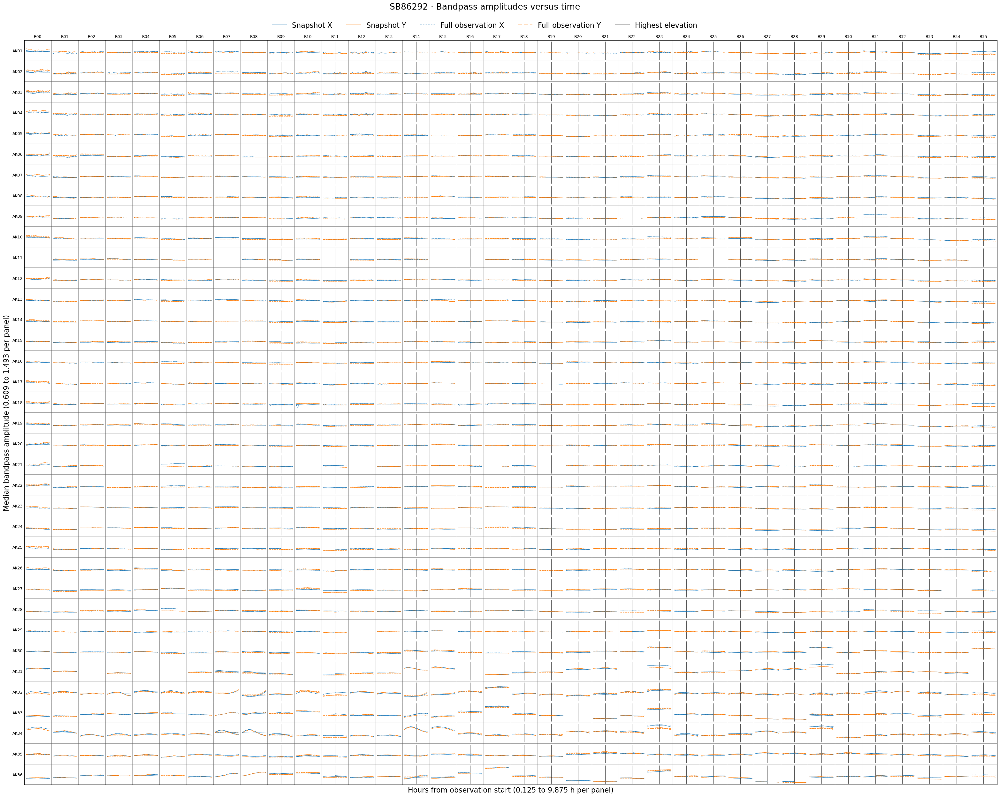

In [357]:
plot_bandpass(sb86292, fontsize=16)


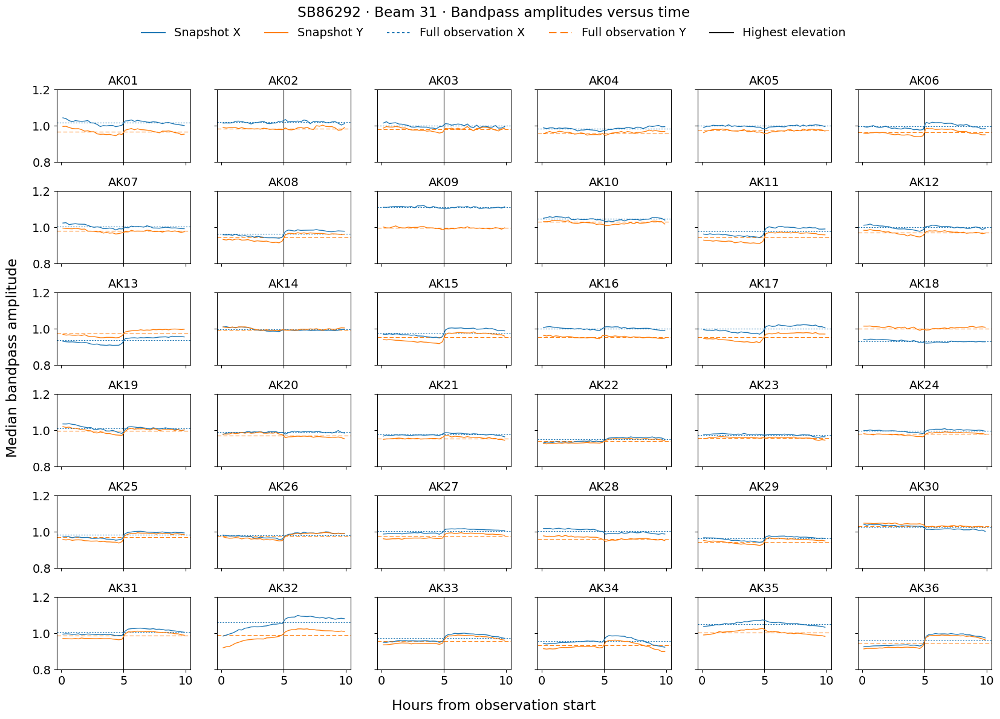

In [358]:
plot_bandpass(sb86292, beam=31, ylim=(0.8, 1.2), fontsize=14)


/Users/cordun/Documents/Australia/CSIRO/time_dep/plots/86292/SB86292_bandpass_amplitude_beam33_all_antennas.pdf


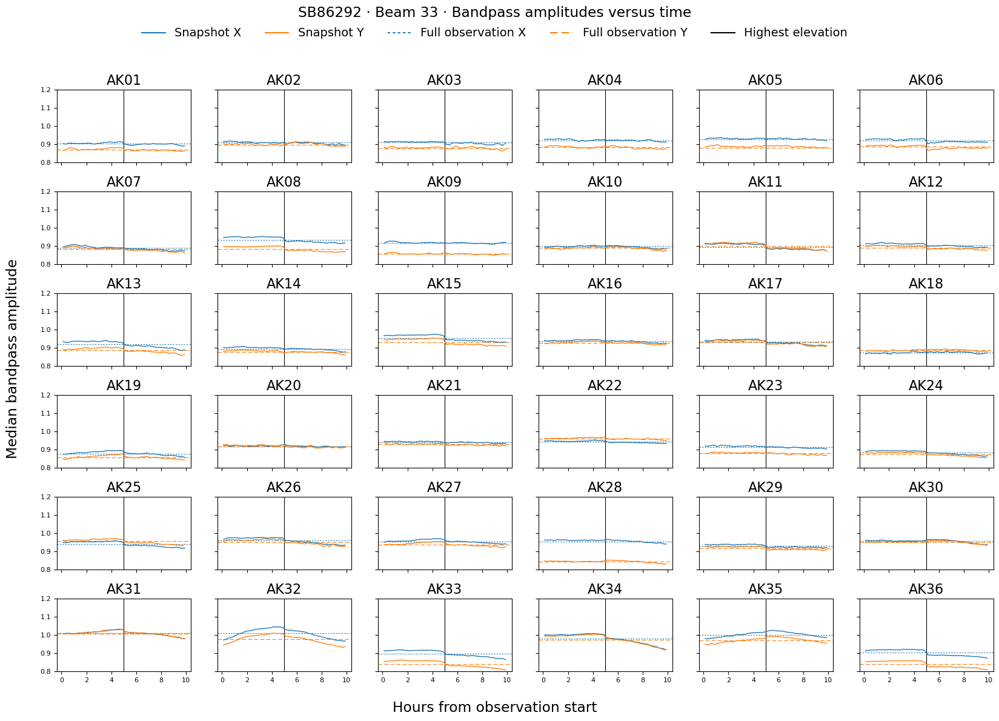

In [342]:
plt.rcParams.update({"font.size": 14})
plot_bandpass(sb86292, beam=33, ylim=(0.8, 1.2))


/Users/cordun/Documents/Australia/CSIRO/time_dep/plots/86292/SB86292_bandpass_amplitude_AK36_all_beams.pdf


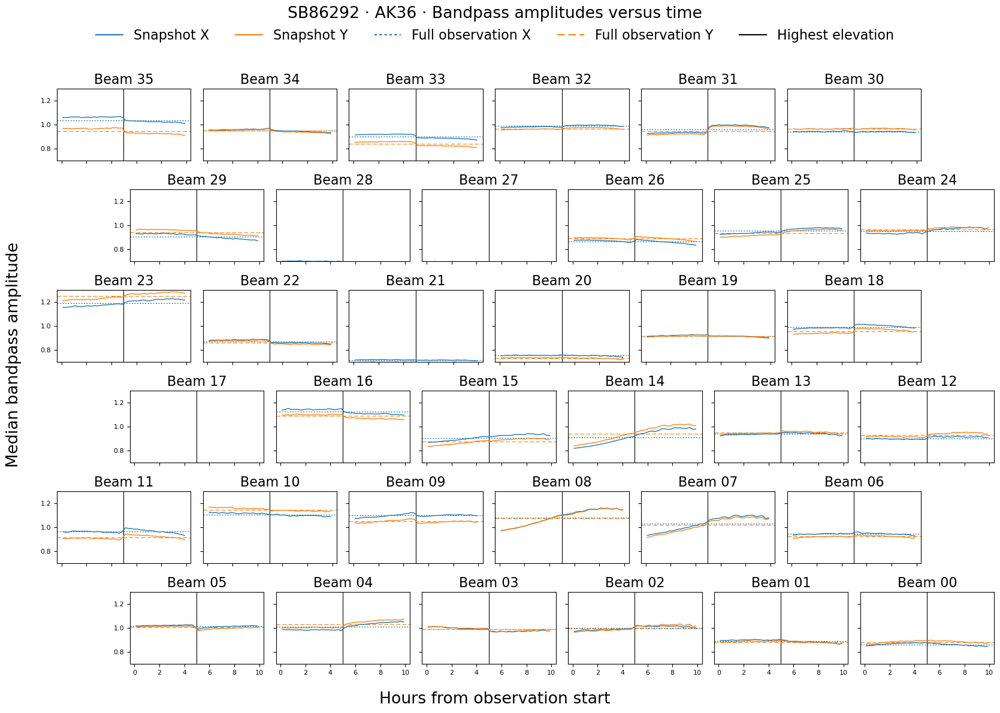

In [332]:
plot_bandpass(sb86292, antenna=36, ylim=(0.7, 1.3))

# One beam and antenna, if needed:
# plot_bandpass(sb86292, beam=33, antenna=4)


## Flux scale and RMS before calibration


In [333]:
for branch in ("before", "after"):
    for metric in ("flux_scale", "rms", "ra", "dec", "leakage"):
        plot_time_metric(sb86292, metric, branch=branch)


SB86292 · Flux scale · before (dimensionless)
Median: 0.9086
Min:    0.8955
Max:    0.9186
Std:    0.0051

SB86292 · RMS · before (µJy/beam)
Median: 207.9965
Min:    202.6420
Max:    229.2265
Std:    4.2177

SB86292 · RA offset · before (arcsec)
Median: -0.0096
Min:    -0.1075
Max:    0.0732
Std:    0.0403

SB86292 · Dec offset · before (arcsec)
Median: 0.0099
Min:    -0.0233
Max:    0.0403
Std:    0.0145

SB86292 · Stokes Q leakage · before (%)
Median: 0.8701
Min:    0.6848
Max:    1.2973
Std:    0.1119

SB86292 · Flux scale · after (dimensionless)
Median: 1.0058
Min:    1.0010
Max:    1.0164
Std:    0.0026

SB86292 · RMS · after (µJy/beam)
Median: 212.6123
Min:    205.2224
Max:    231.5170
Std:    4.5718

SB86292 · RA offset · after (arcsec)
Median: -0.0126
Min:    -0.1084
Max:    0.0683
Std:    0.0311

SB86292 · Dec offset · after (arcsec)
Median: 0.0193
Min:    -0.0158
Max:    0.0532
Std:    0.0144

SB86292 · Stokes Q leakage · after (%)
Median: 1.3073
Min:    1.0185
Max:    1.566

## Source flux ratios across the field

Three comparisons: the earliest available pair before rotation, a pair across rotation, and the latest available pair after rotation. `bin_gap` is the difference between bin numbers. Only bins entirely on the required side of the rotation marker are used; source validity is checked separately for each pair.


Before jump: bin-006 / bin-000


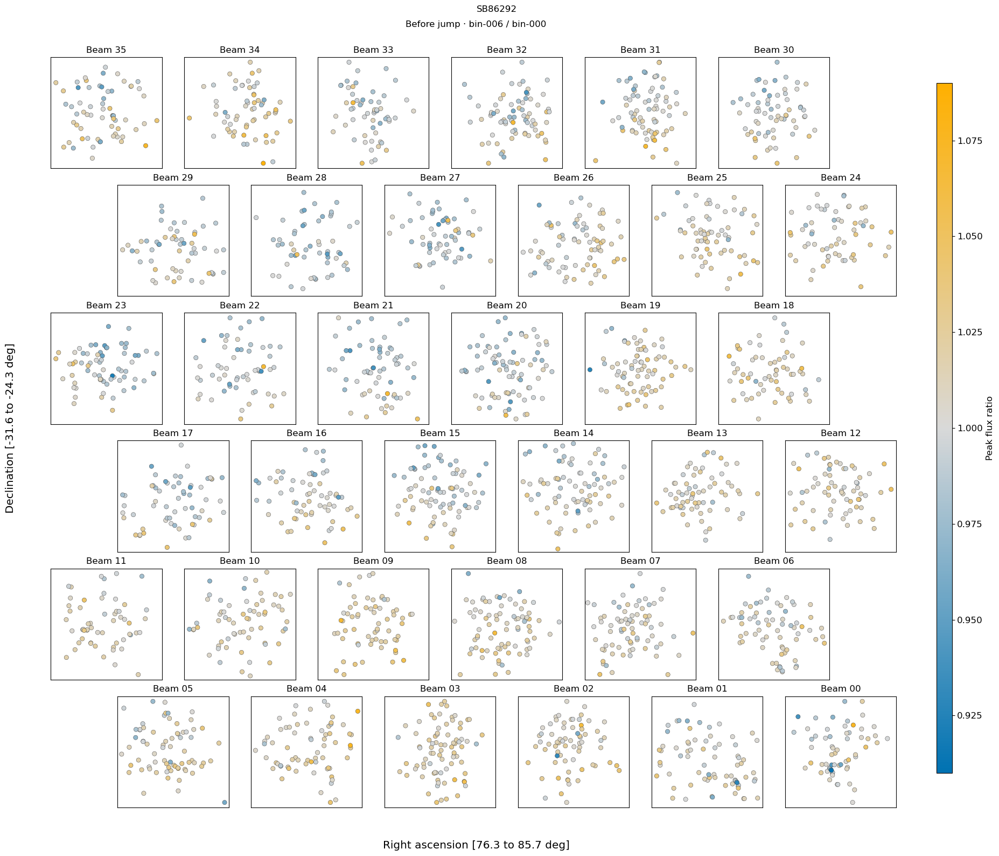

Across jump: bin-022 / bin-016


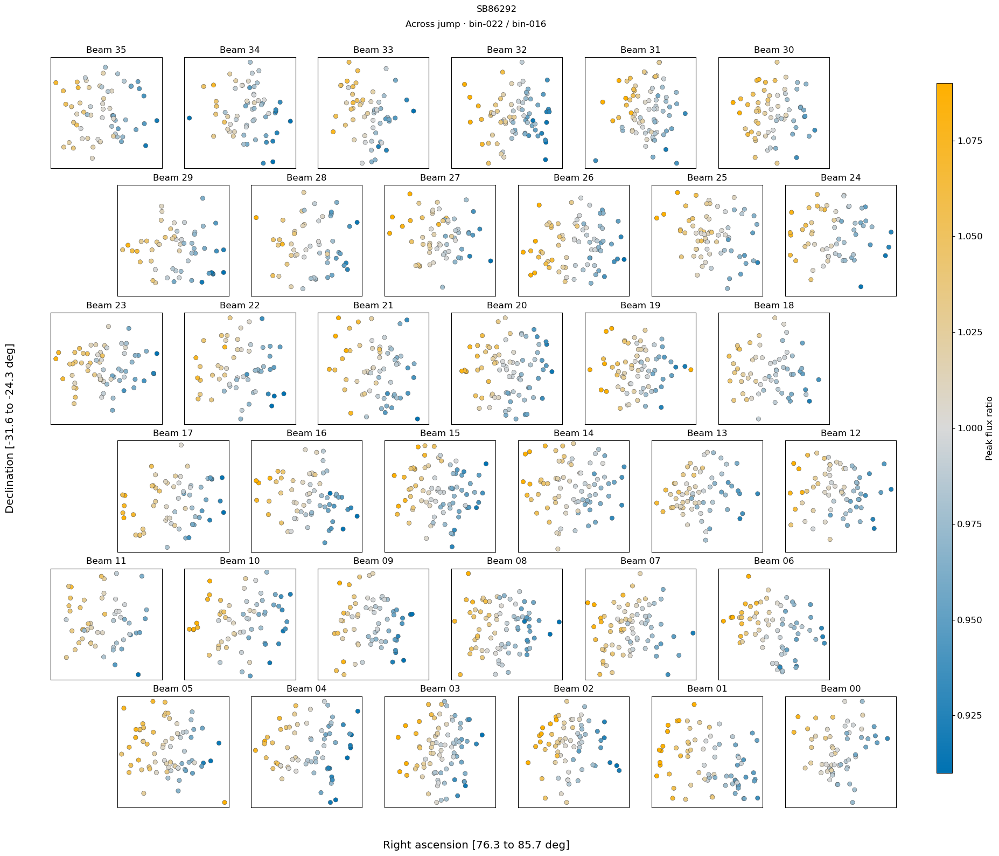

After jump: bin-038 / bin-032


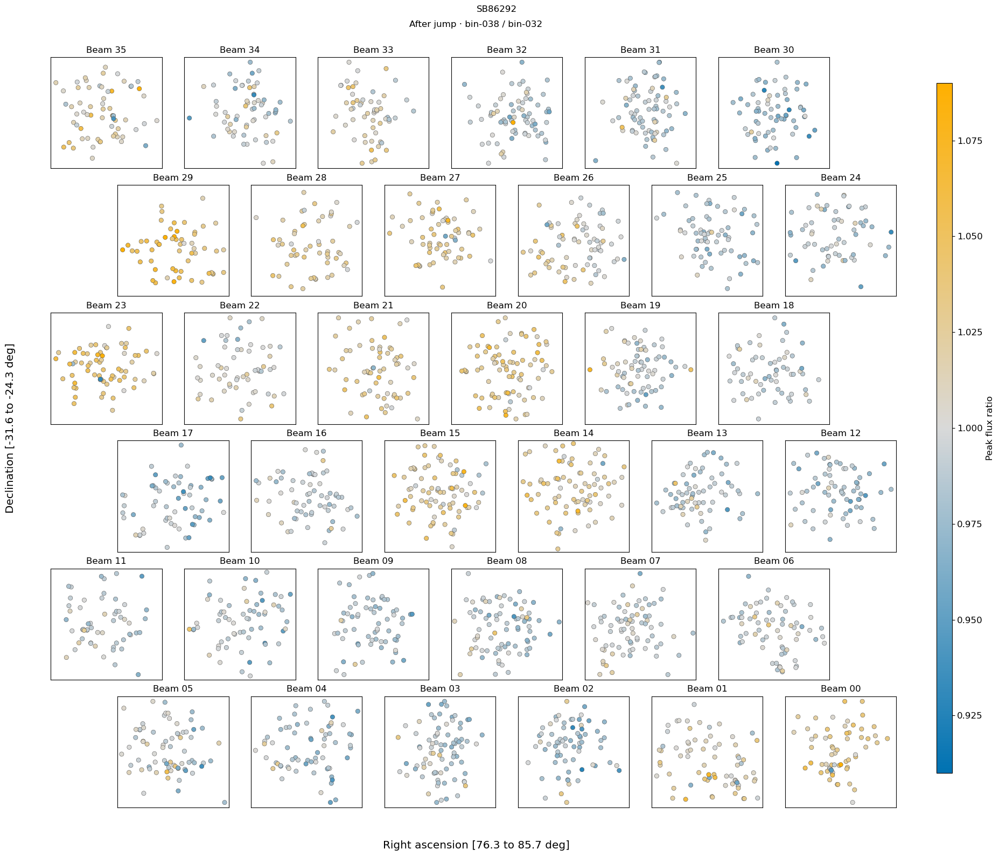

In [435]:
ratio_pairs_86292 = plot_source_ratios(sb86292, bin_gap=6, last_bin=38, min_flux_mjy=10, vmin=0.91, vmax=1.09, dot_size=35, fontsize=12)


## One east and one west source per beam

Select the brightest reference-bin source on each side, at least 0.8 degree east/west of the beam centre and within 0.25 degree north/south. Track the same sources through time. No maximum east/west distance or later flux cut is applied. Each beam is selected independently, so overlapping beams may select the same physical source.


SB86292 · bin-019 → bin-020
Change = 100 × (after / before − 1)
Direction   Sources   Mean (%)   Median (%)
East            35      4.245        4.049


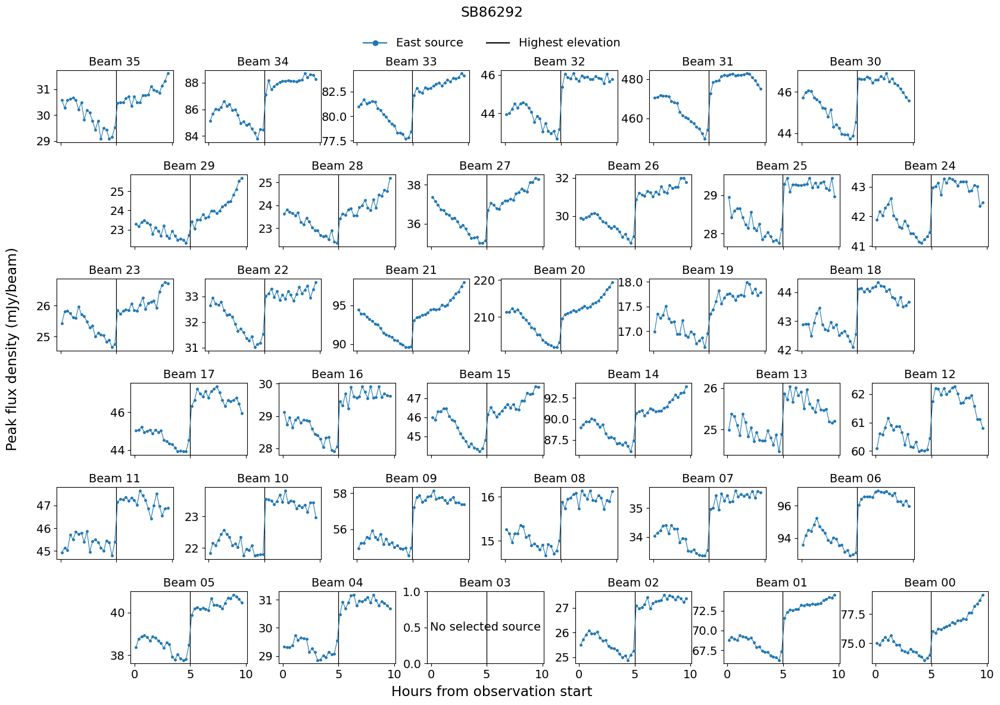

West            36     -4.478       -4.070


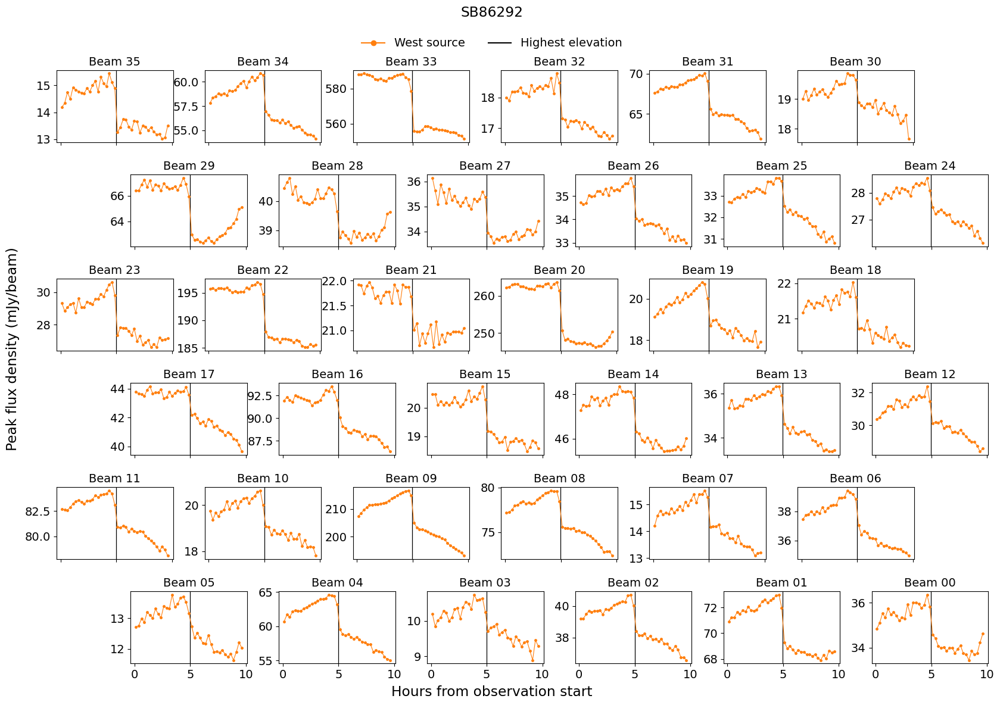

In [446]:
lightcurves_86292 = plot_source_lightcurves(sb86292, min_flux_mjy=10, min_east_west_deg=0.8, north_half_width_deg=0.3, last_bin=38, fontsize=14)


## Bandpass X/Y

The same bandpass function also supports a single beam or antenna with `ratio=True`.


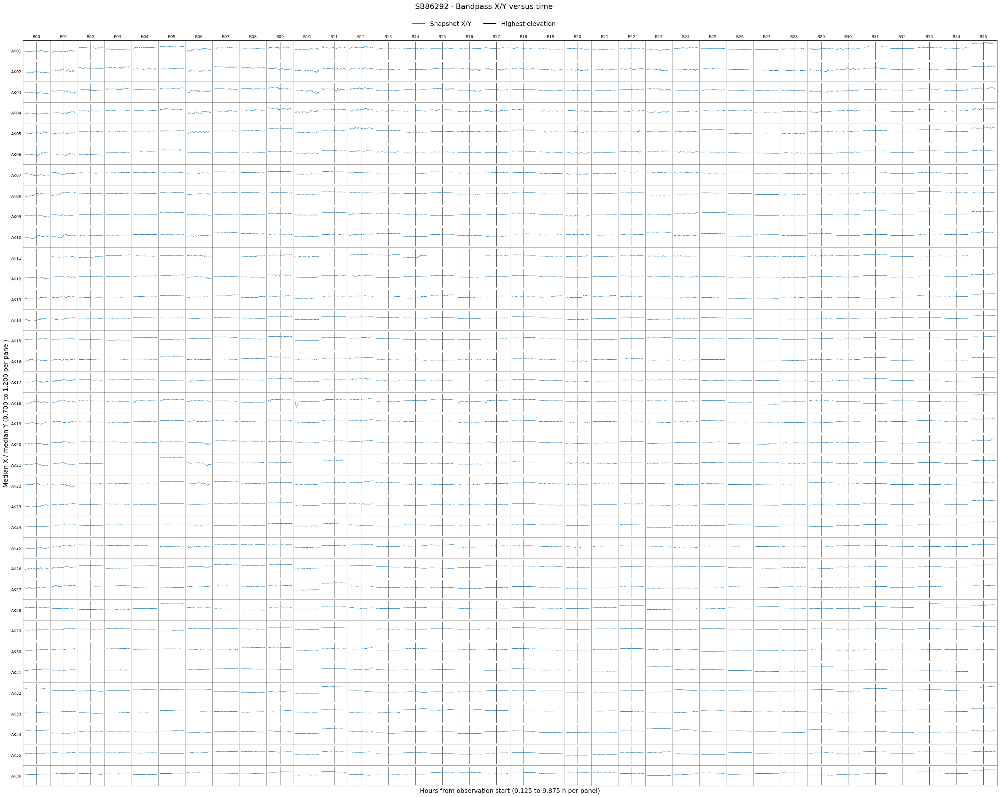

In [501]:
plot_bandpass(sb86292, ratio=True, ylim=(0.7, 1.2))


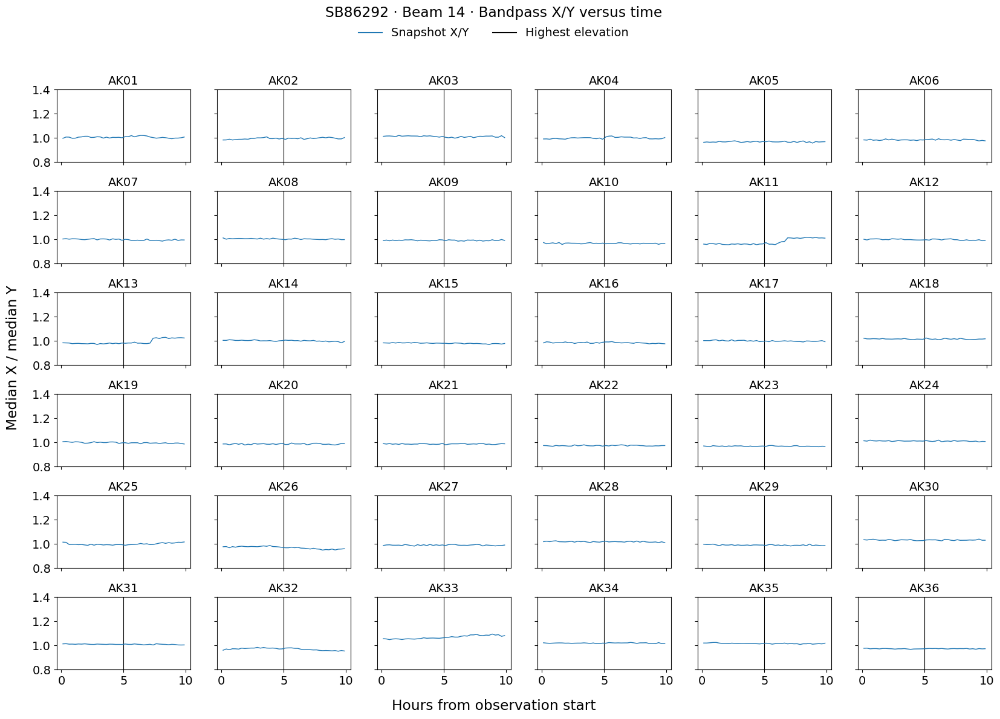

In [504]:
plot_bandpass(sb86292, beam=14, ylim=(0.8, 1.4), fontsize=14,ratio=True)


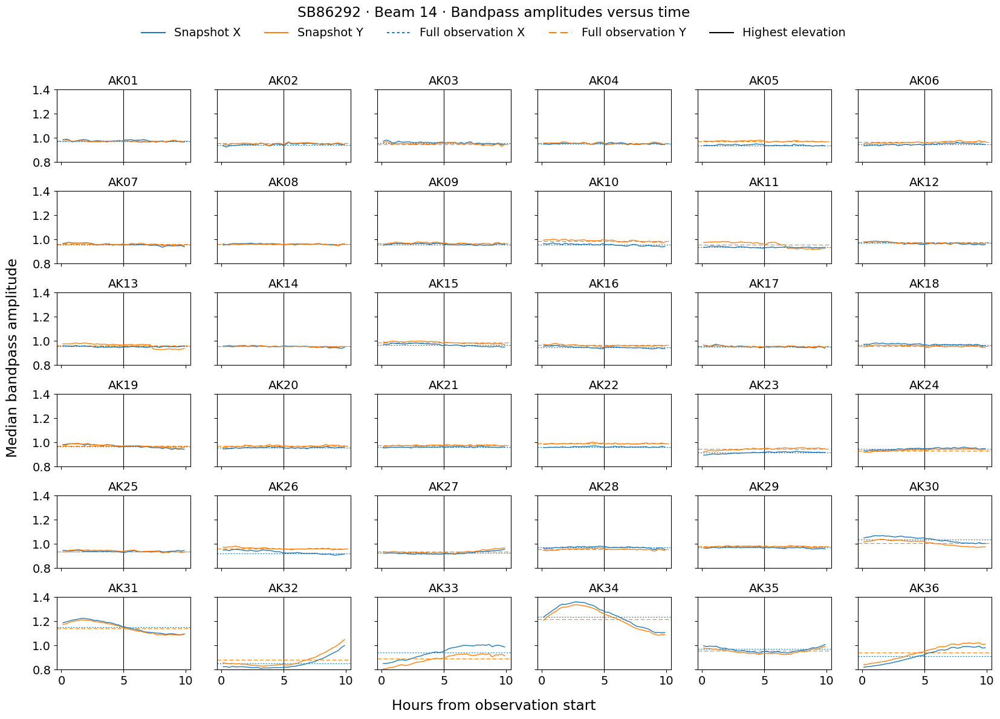

In [496]:
plot_bandpass(sb86292, beam=14, ylim=(0.8, 1.4), fontsize=14,ratio=False)


## POLANGLE, azimuth and elevation

Each figure shows all antennas. The orange marker is the median azimuth sign-change time nearest the POLANGLE marker, or the median time of maximum recorded elevation. Sign changes and fastest changes use consecutive tracked records, excluding long metadata gaps.


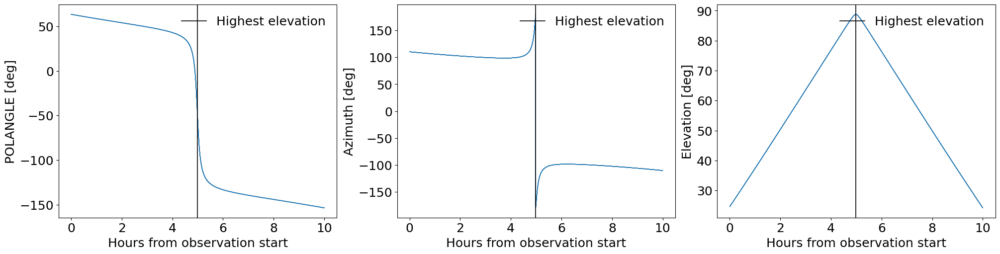

In [380]:
plot_pointing_angles(sb86292, fontsize=18)


## Amplitude change across zenith


SB86292 · Beam 31: bin-019 (4.875 h) → bin-020 (5.125 h)
SB86292 · Beam 11: bin-019 (4.875 h) → bin-020 (5.125 h)


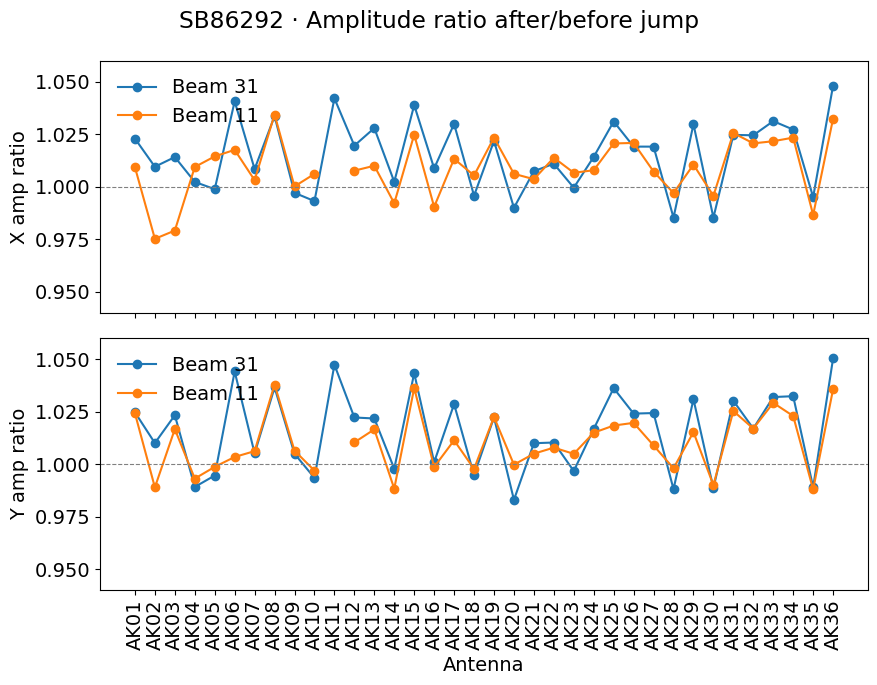

SB86292 · Beam 09: bin-019 (4.875 h) → bin-020 (5.125 h)
SB86292 · Beam 11: bin-019 (4.875 h) → bin-020 (5.125 h)


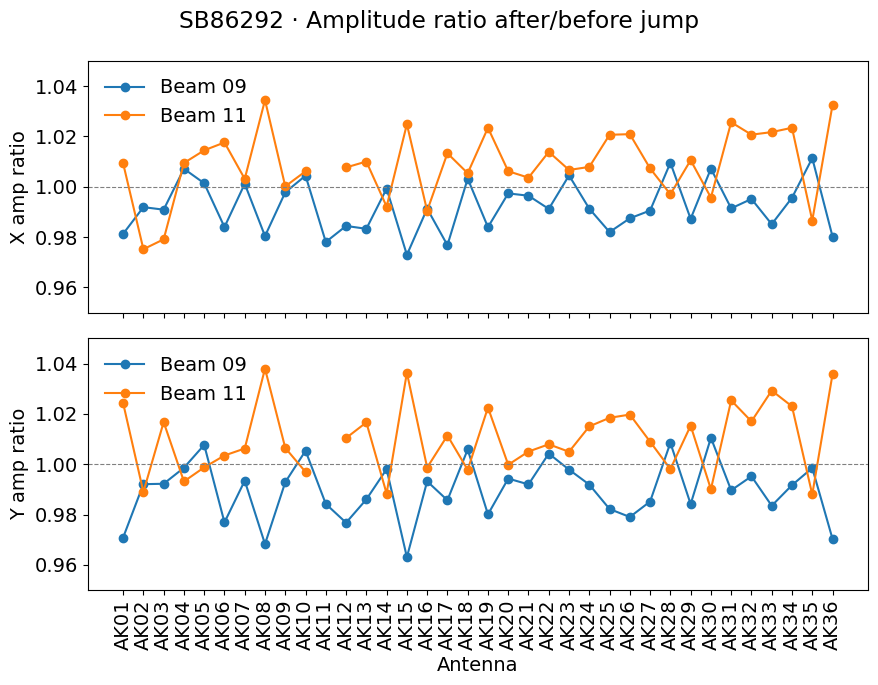

In [20]:
plot_amplitude_jump([(sb86292, 31), (sb86292, 11)], ymin = 0.94, ymax = 1.06)

# Optional beam-9 comparisons:
plot_amplitude_jump([(sb86292, 9), (sb86292, 11)])
# plot_amplitude_jump([(sb86292, 9), (sb86292, 11)], invert=[("86292", 9)])


SB86292 · Beam 31: bin-019 (4.875 h) → bin-020 (5.125 h)
SB86292 · Beam 11: bin-019 (4.875 h) → bin-020 (5.125 h)


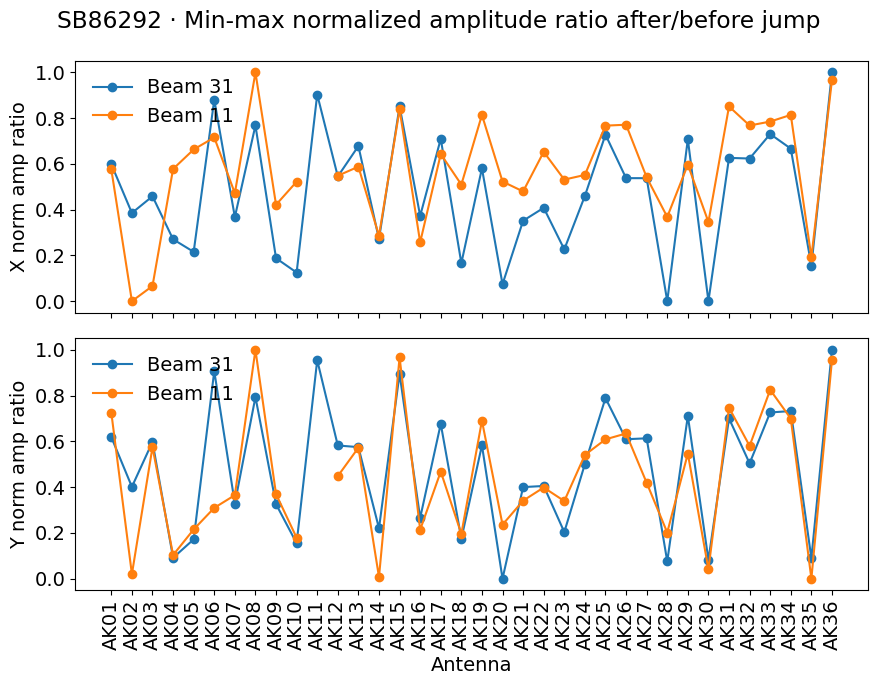

In [21]:
plot_amplitude_jump([(sb86292, 31), (sb86292, 11)], normalization=True)



# SB61078


In [25]:
sb61078 = load_time_data("61078")


SB61078: 28 measurement bins; 29 source bins (before calibration); rotation marker 4.5246 h


## Bandpass amplitudes

All beams and antennas, then selected views. Use `ylim=None` for automatic limits.


/Users/cordun/Documents/Australia/CSIRO/time_dep/plots/61078/SB61078_bandpass_amplitude_all_beams_all_antennas.pdf


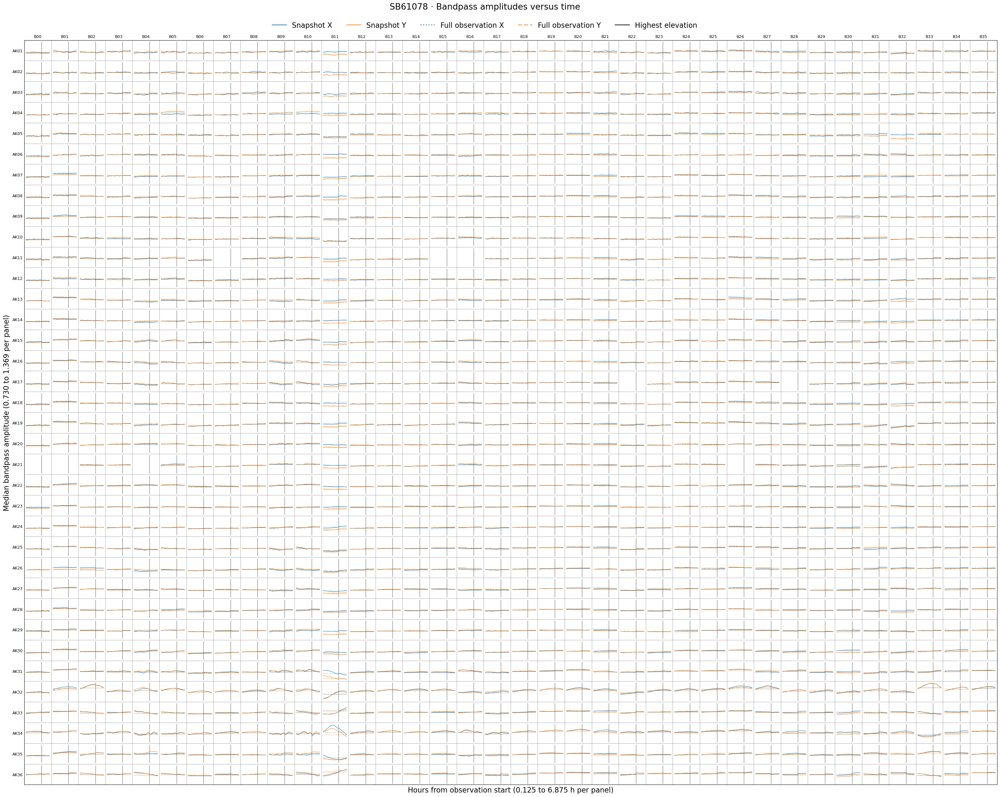

In [340]:
plot_bandpass(sb61078)


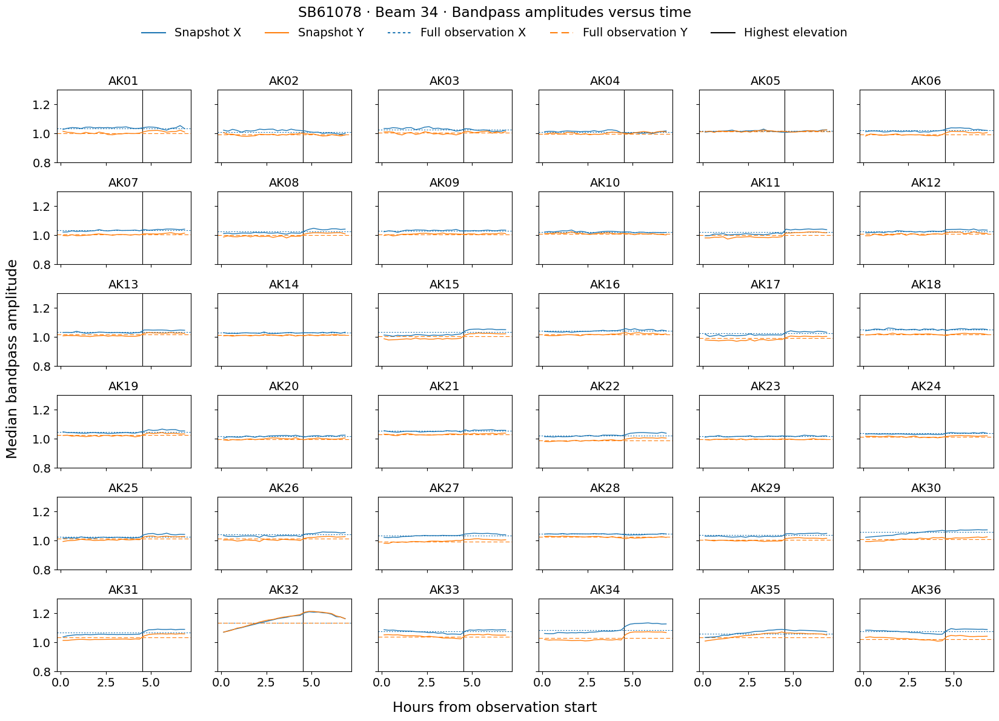

In [354]:
plot_bandpass(sb61078, beam=34, ylim=(0.8, 1.3), fontsize=14)


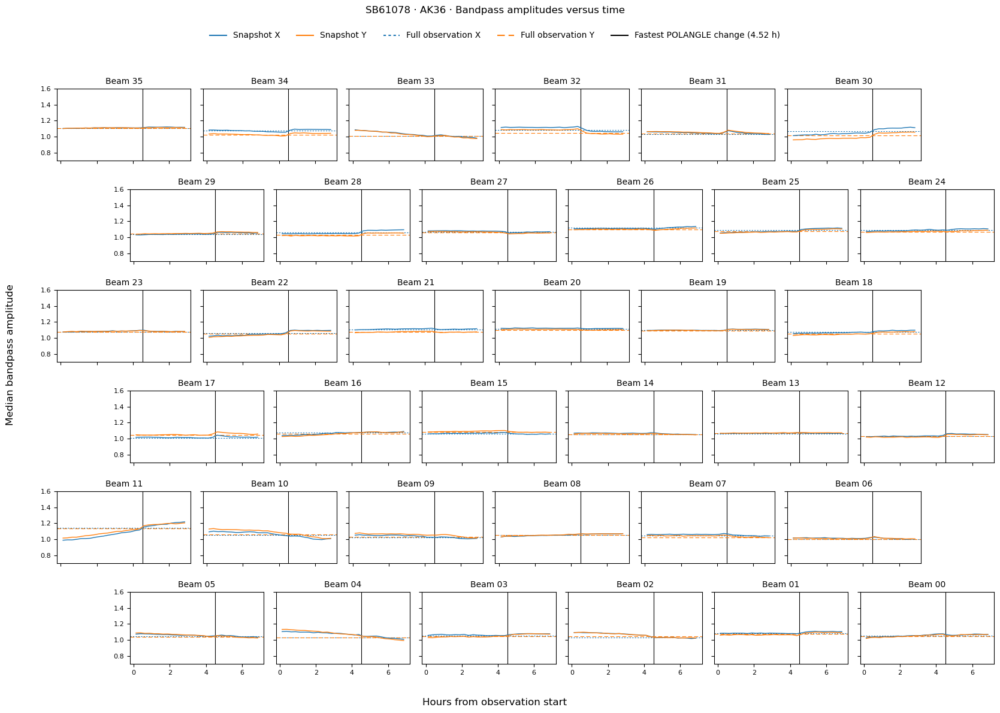

In [213]:
plot_bandpass(sb61078, antenna=36, ylim=(0.7, 1.6))


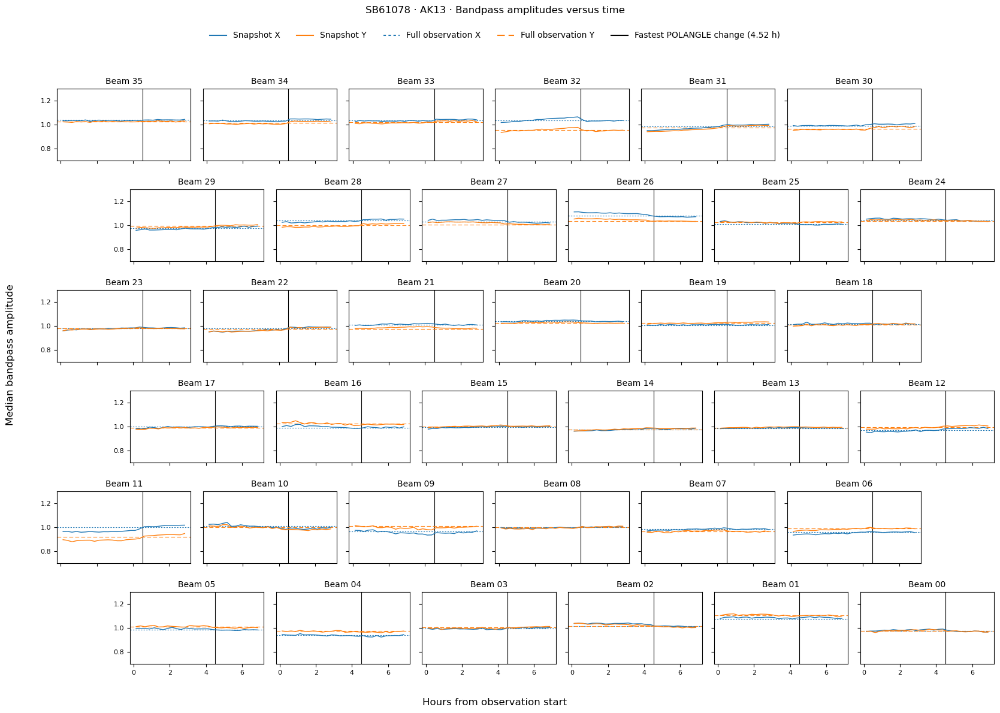

In [214]:
plot_bandpass(sb61078, antenna=13, ylim=(0.7, 1.3))

# One beam and antenna, if needed:
# plot_bandpass(sb61078, beam=33, antenna=4)


## Flux scale and RMS before calibration


In [243]:
for branch in ("before", "after"):
    for metric in ("flux_scale", "rms", "ra", "dec", "leakage"):
        plot_time_metric(sb61078, metric, branch=branch)


SB61078 · Flux scale · before (dimensionless)
Median: 1.0188
Min:    1.0106
Max:    1.0265
Std:    0.0045

SB61078 · RMS · before (µJy/beam)
Median: 224.7131
Min:    222.2158
Max:    230.5469
Std:    1.7427

SB61078 · RA offset · before (arcsec)
Median: -0.7037
Min:    -1.0065
Max:    -0.5754
Std:    0.1094

SB61078 · Dec offset · before (arcsec)
Median: 0.1588
Min:    0.1246
Max:    0.1971
Std:    0.0172

SB61078 · Stokes Q leakage · before (%)
Median: 0.6895
Min:    0.4995
Max:    1.0570
Std:    0.1075

SB61078 · Flux scale · after (dimensionless)
Median: 1.0086
Min:    1.0043
Max:    1.0146
Std:    0.0026

SB61078 · RMS · after (µJy/beam)
Median: 210.8744
Min:    208.0380
Max:    218.8342
Std:    2.6140

SB61078 · RA offset · after (arcsec)
Median: -0.0143
Min:    -0.0697
Max:    0.0220
Std:    0.0218

SB61078 · Dec offset · after (arcsec)
Median: 0.0087
Min:    -0.0437
Max:    0.0529
Std:    0.0194

SB61078 · Stokes Q leakage · after (%)
Median: 1.4428
Min:    1.1944
Max:    1.703

## Source flux ratios across the field

Three comparisons: the earliest available pair before rotation, a pair across rotation, and the latest available pair after rotation. `bin_gap` is the difference between bin numbers. Only bins entirely on the required side of the rotation marker are used; source validity is checked separately for each pair.


Before jump: bin-006 / bin-000


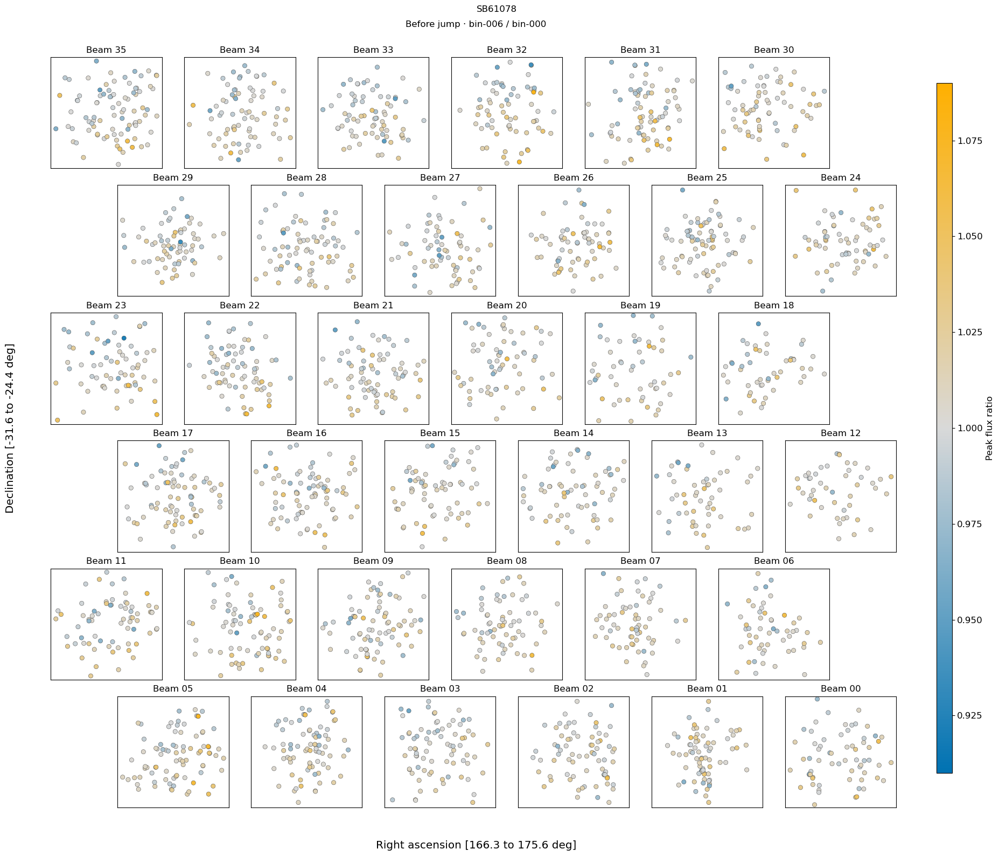

Across jump: bin-021 / bin-015


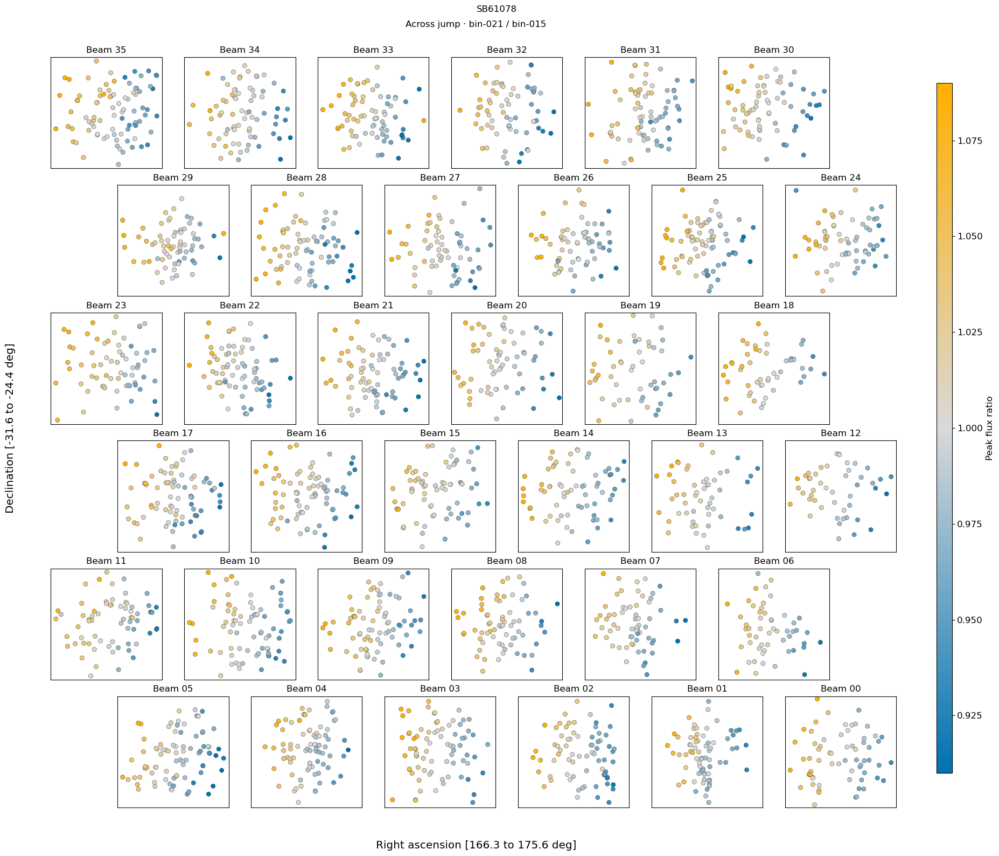

After jump: bin-028 / bin-022


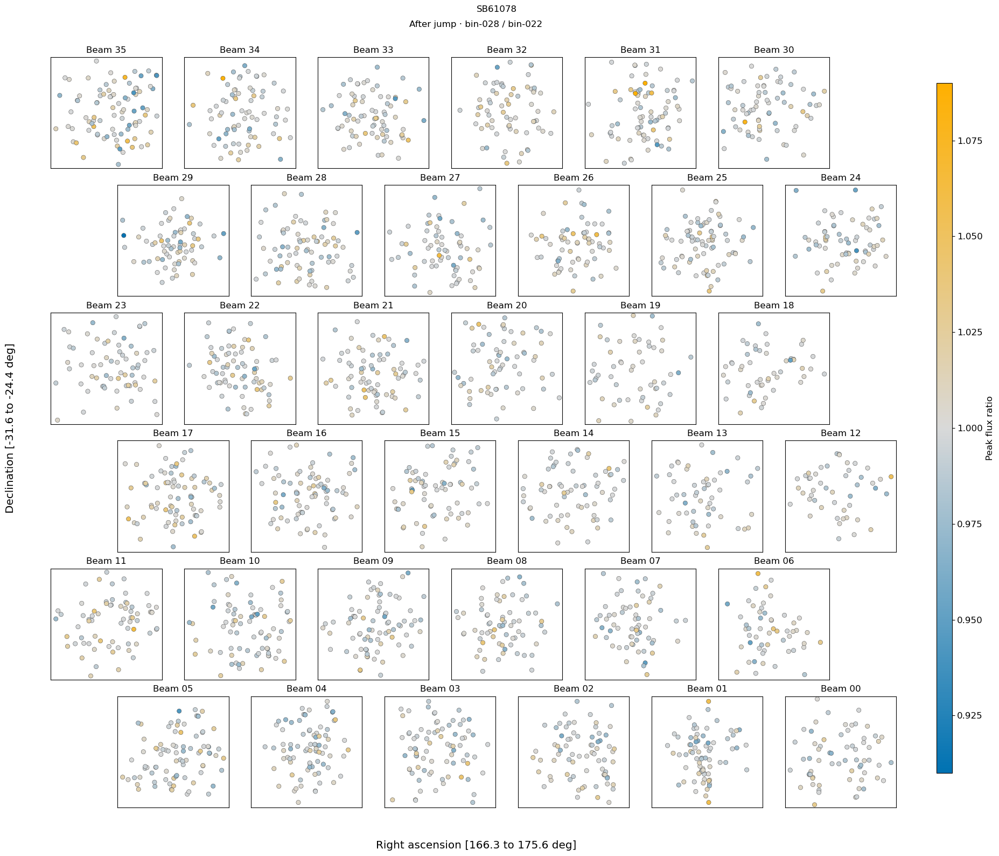

In [436]:
ratio_pairs_61078 = plot_source_ratios(sb61078, bin_gap=6, min_flux_mjy=10, vmin=0.91, vmax=1.09, dot_size=35, fontsize=12)


## One east and one west source per beam

Select the brightest reference-bin source on each side, at least 1 degree east/west of the beam centre and within 0.25 degree north/south. Track the same sources through time. No maximum east/west distance or later flux cut is applied. Each beam is selected independently, so overlapping beams may select the same physical source.

The printed change uses the adjacent snapshot midpoints on either side of the rotation marker; a snapshot itself can span that marker.


SB61078 · bin-017 → bin-018
Change = 100 × (after / before − 1)
Direction   Sources   Mean (%)   Median (%)
East            36      4.201        3.951


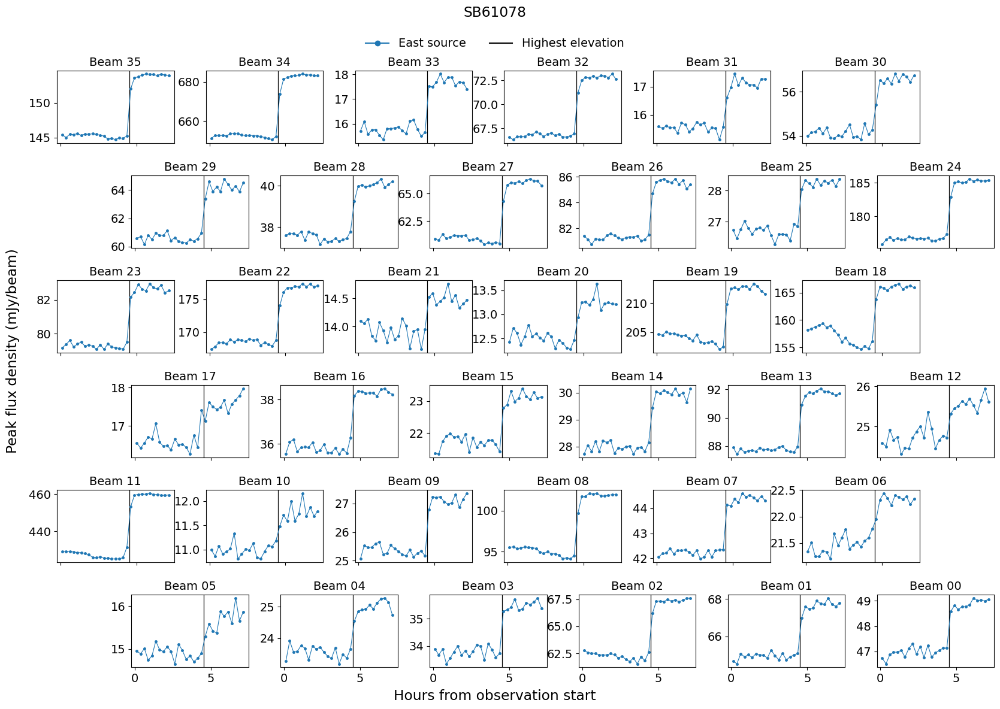

West            35     -2.682       -2.910


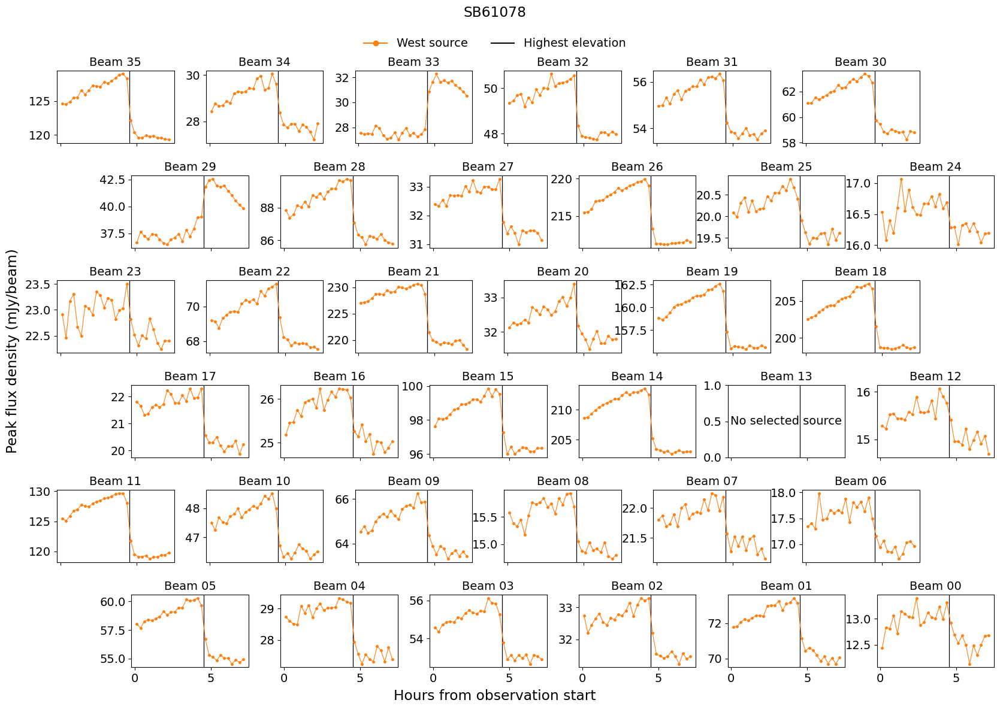

In [445]:
lightcurves_61078 = plot_source_lightcurves(sb61078, min_flux_mjy=10, min_east_west_deg=0.8, north_half_width_deg=0.3, fontsize=14)


## Bandpass X/Y

The same bandpass function also supports a single beam or antenna with `ratio=True`.


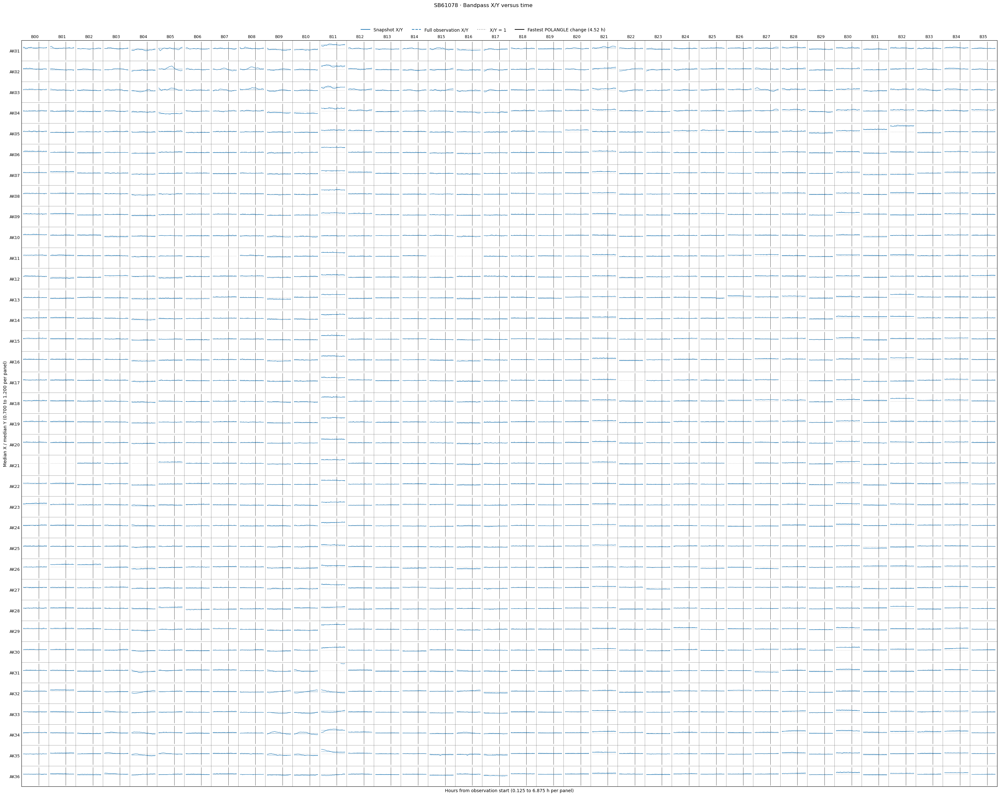

In [219]:
plot_bandpass(sb61078, ratio=True, ylim=(0.7, 1.2))

# plot_bandpass(sb61078, antenna=4, ratio=True)
# plot_bandpass(sb61078, beam=33, ratio=True)


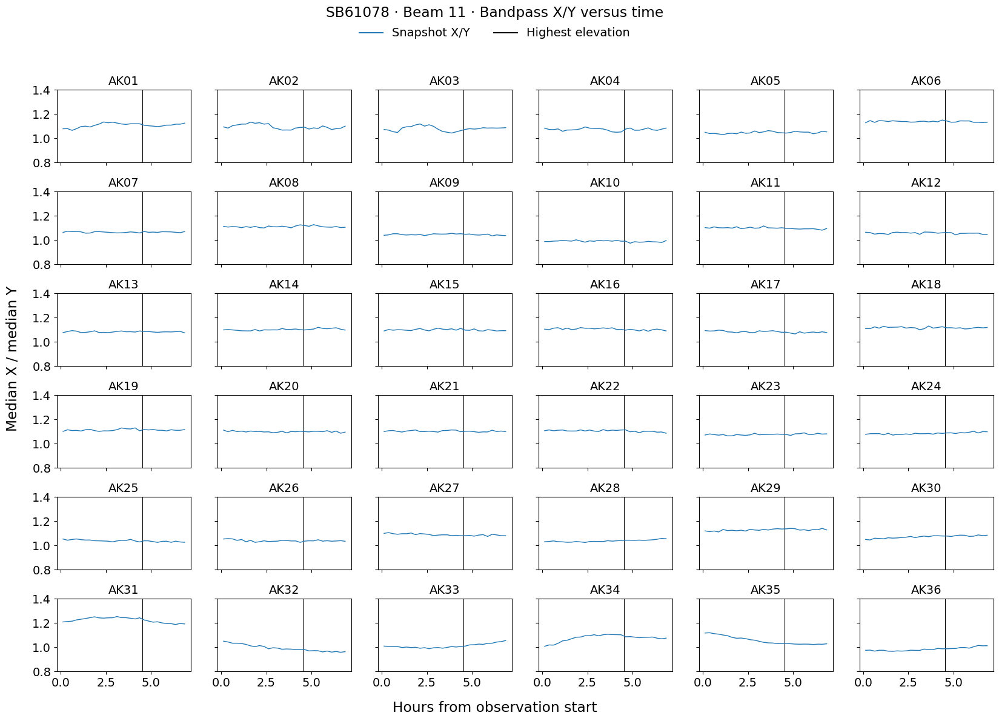

In [505]:
plot_bandpass(sb61078, beam=11, ylim=(0.8, 1.4), fontsize=14,ratio=True)


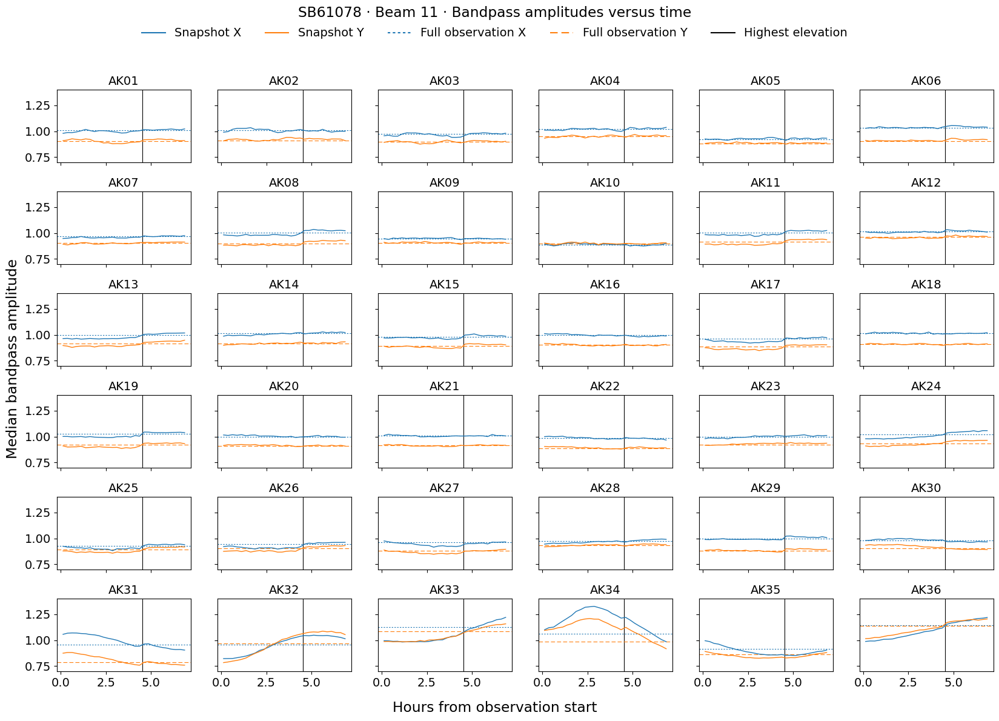

In [506]:
plot_bandpass(sb61078, beam=11, ylim=(0.7, 1.4), fontsize=14,ratio=False)


## POLANGLE, azimuth and elevation

Each figure shows all antennas. The orange marker is the median azimuth sign-change time nearest the POLANGLE marker, or the median time of maximum recorded elevation. Sign changes and fastest changes use consecutive tracked records, excluding long metadata gaps.


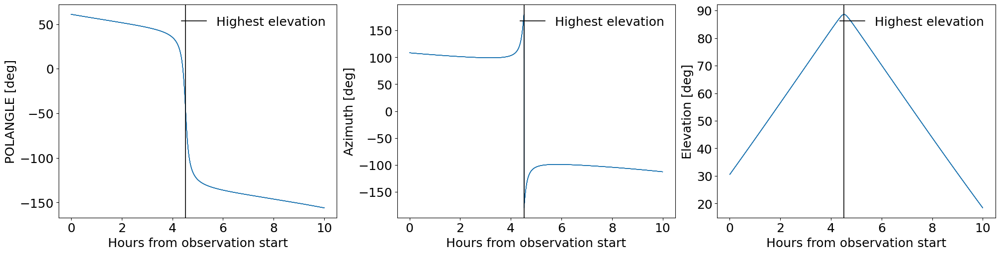

In [381]:
plot_pointing_angles(sb61078, fontsize=18)


## Amplitude change across zenith


SB61078 · Beam 28: bin-017 (4.375 h) → bin-018 (4.625 h)
SB61078 · Beam 34: bin-017 (4.375 h) → bin-018 (4.625 h)


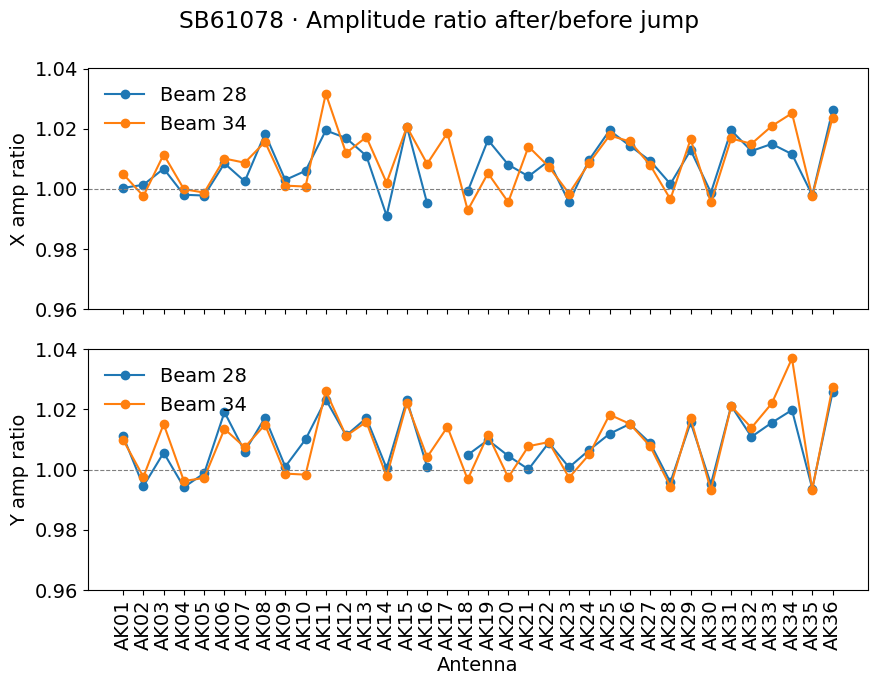

In [31]:
jump_ratios_61078 = plot_amplitude_jump([(sb61078, 28), (sb61078, 34)], ymin = 0.96, ymax = 1.04)


SB61078 · Beam 28: bin-017 (4.375 h) → bin-018 (4.625 h)
SB61078 · Beam 34: bin-017 (4.375 h) → bin-018 (4.625 h)


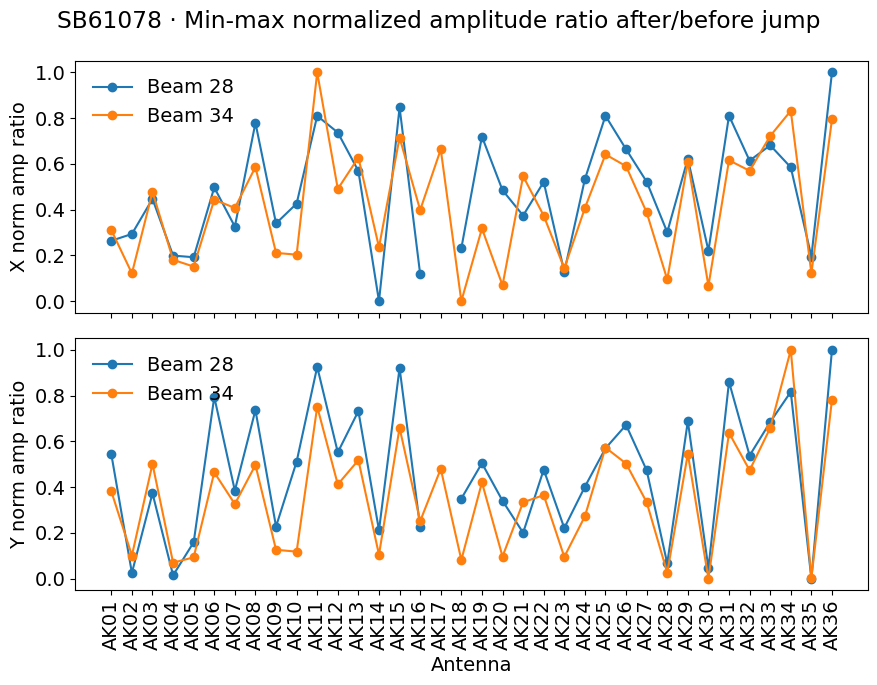

In [32]:
jump_ratios_61078 = plot_amplitude_jump([(sb61078, 28), (sb61078, 34)], normalization=True)

# Comparison between observations

Each curve uses the snapshots bracketing its own observation's fastest roll-angle change. The ratio is after/before rotation. In the optional beam-9 call above, the reciprocal is explicitly requested and labelled before/after. No reference-antenna or min–max normalisation is applied.


SB86292 · Beam 31: bin-019 (4.875 h) → bin-020 (5.125 h)
SB61078 · Beam 34: bin-017 (4.375 h) → bin-018 (4.625 h)


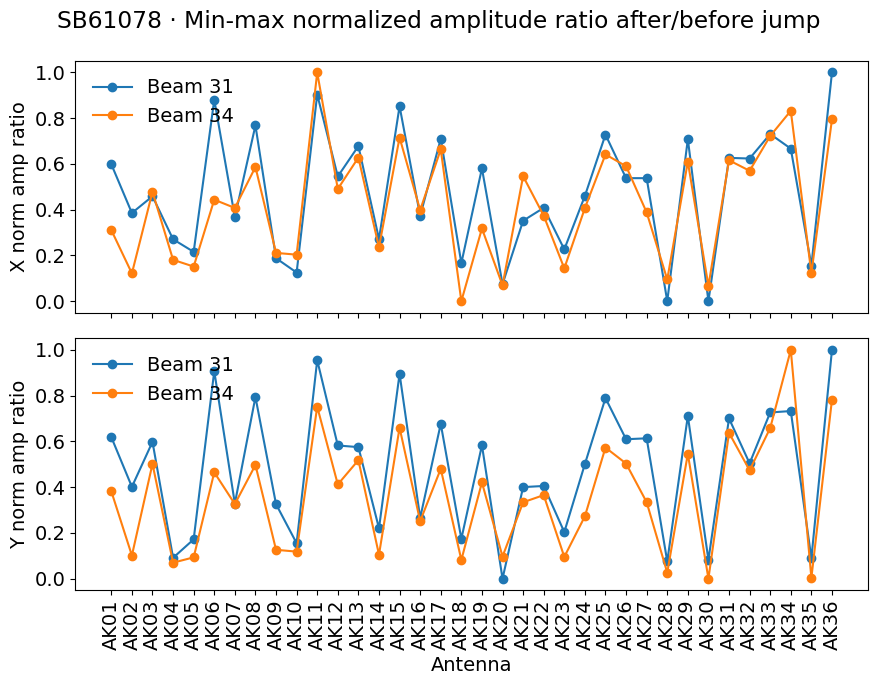

In [33]:
comparison_ratios = plot_amplitude_jump([(sb86292, 31), (sb61078, 34)], normalization=True)


# Make images

In [282]:
from pathlib import Path

import astropy.units as u
import matplotlib.pyplot as plt
import numpy as np
from astropy.coordinates import SkyCoord
from astropy.io import fits
from astropy.nddata import Cutout2D
from astropy.wcs import WCS
from matplotlib.colors import PowerNorm

plt.rcParams.update({"font.size": 16})

base = Path.home() / "Documents/Australia/CSIRO/time_dep"


def compare_snapshot_images(obs_id, bin_number=19, ra=None, dec=None, size=20, vmin=0, vmax=1, gamma=0.5, cmap="magma"):
    """Compare before/after mosaics; optional cutout size is in arcminutes."""

    obs_id = str(obs_id)
    image_dir = base / "images" / obs_id / f"bin-{bin_number:03d}"
    plot_dir = base / "plots" / obs_id
    files = {branch: image_dir / f"{branch}.fits" for branch in ("before", "after")}

    missing = [path for path in files.values() if not path.is_file()]

    if missing:
        print(f"SB{obs_id}: missing images; skipping.")
        for path in missing:
            print(path)
        return

    if (ra is None) != (dec is None):
        raise ValueError("Supply both RA and Dec, or leave both as None.")

    position = None if ra is None else SkyCoord(ra * u.deg, dec * u.deg, frame="icrs")
    norm = PowerNorm(gamma=gamma, vmin=vmin, vmax=vmax)

    fig = plt.figure(figsize=(14, 6), layout="constrained")
    axes = []

    for i, (branch, path) in enumerate(files.items()):
        with fits.open(path, memmap=True) as hdul:
            hdu = hdul[0]
            image = np.squeeze(hdu.data)
            wcs = WCS(hdu.header).celestial
            factor = u.Unit(hdu.header.get("BUNIT", "Jy/beam")).to(u.mJy / u.beam)

            if position is not None:
                cutout = Cutout2D(image, position, size * u.arcmin, wcs=wcs, mode="partial", fill_value=np.nan)
                image, wcs = cutout.data, cutout.wcs

            image = np.array(image, dtype=np.float32, copy=True)
            image *= factor

        ax = fig.add_subplot(1, 2, i + 1, projection=wcs)
        im = ax.imshow(image, origin="lower", cmap=cmap, norm=norm, interpolation="nearest")
        ax.set_title(f"{branch.capitalize()} additional calibration", fontsize=16)
        ax.set_xlabel("Right ascension")

        if i == 0:
            ax.set_ylabel("Declination")
        else:
            ax.set_ylabel("")
            ax.coords[1].set_ticklabel_visible(False)

        axes.append(ax)

    fig.suptitle(f"SB{obs_id} · bin-{bin_number:03d}", fontsize=16)
    fig.colorbar(im, ax=axes, label="Flux density (mJy/beam)", shrink=0.85, pad=0.02)

    plot_dir.mkdir(parents=True, exist_ok=True)
    output = plot_dir / f"SB{obs_id}_bin{bin_number:03d}_before_after_example.pdf"
    fig.savefig(output, dpi=300, bbox_inches="tight")
    print(f"Saved: {output}")

    plt.show()
    plt.close(fig)

Saved: /Users/cordun/Documents/Australia/CSIRO/time_dep/plots/61078/SB61078_bin019_before_after_example.pdf


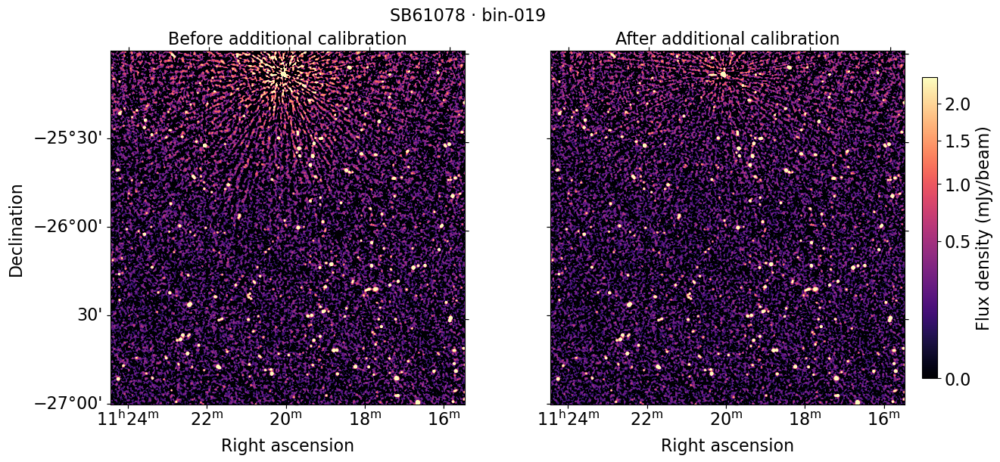

In [283]:
compare_snapshot_images("61078", ra=170.0, dec=-26, size=120, vmin=0.001, vmax=2.4)

Saved: /Users/cordun/Documents/Australia/CSIRO/time_dep/plots/86292/SB86292_bin019_before_after_example.pdf


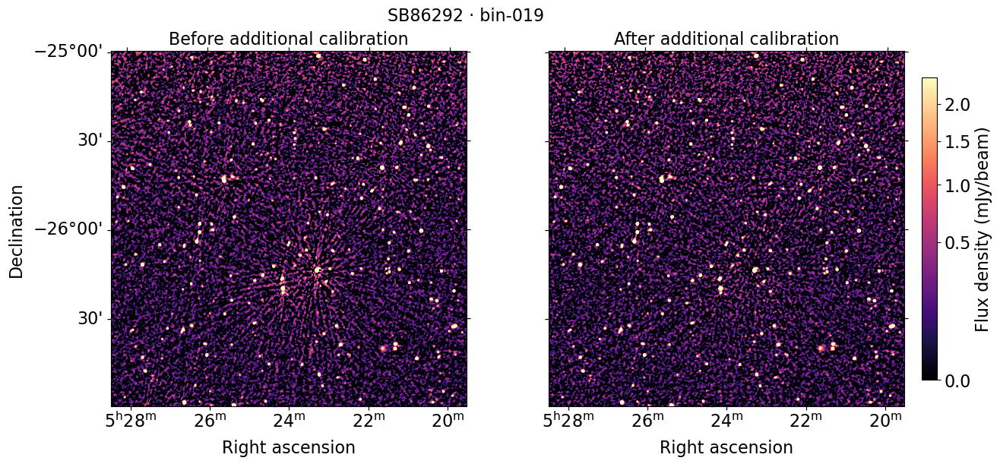

In [403]:
compare_snapshot_images("86292", vmin=0.001, vmax=2.4, ra=81, dec=-26,size=120)

In [400]:
from pathlib import Path

import astropy.units as u
import matplotlib.pyplot as plt
import numpy as np
from astropy.io import fits
from astropy.wcs import WCS
from matplotlib.colors import PowerNorm

plt.rcParams.update({"font.size": 16})

base = Path.home() / "Documents/Australia/CSIRO/time_dep"


def compare_beam_images(obs_id, beams, vmin=0, vmax=1, gamma=0.5, cmap="magma"):
    """Compare two full-track, after-calibration beam images."""

    obs_id = str(obs_id)

    if len(beams) != 2:
        raise ValueError("Choose two beam numbers.")

    image_dir = base / "images" / obs_id / "full_after"
    plot_dir = base / "plots" / obs_id
    plot_dir.mkdir(parents=True, exist_ok=True)

    norm = PowerNorm(gamma=gamma, vmin=vmin, vmax=vmax)
    fig = plt.figure(figsize=(14, 6), layout="constrained")
    axes = []

    for i, beam in enumerate(beams):
        path = image_dir / f"beam{beam:02d}.fits"

        with fits.open(path, memmap=True) as hdul:
            hdu = hdul[0]
            image = np.array(np.squeeze(hdu.data), dtype=np.float32, copy=True)
            wcs = WCS(hdu.header).celestial
            image *= u.Unit(hdu.header.get("BUNIT", "Jy/beam")).to(u.mJy / u.beam)

        ax = fig.add_subplot(1, 2, i + 1, projection=wcs)
        im = ax.imshow(image, origin="lower", cmap=cmap, norm=norm, interpolation="nearest")

        ax.set_title(f"Beam {beam:02d}")
        ax.set_xlabel("Right ascension")

        if i == 0:
            ax.set_ylabel("Declination")
        else:
            ax.set_ylabel("")
            ax.coords[1].set_ticklabel_visible(False)

        axes.append(ax)

    fig.suptitle(f"SB{obs_id}")
    fig.colorbar(im, ax=axes, label="Flux density (mJy/beam)", shrink=0.85, pad=0.02)

    output = plot_dir / f"SB{obs_id}_beam{beams[0]:02d}_beam{beams[1]:02d}_full_after.pdf"
    fig.savefig(output, dpi=300, bbox_inches="tight")
    print(f"Saved: {output}")

    plt.show()
    plt.close(fig)

Saved: /Users/cordun/Documents/Australia/CSIRO/time_dep/plots/86292/SB86292_beam31_beam23_full_after.pdf


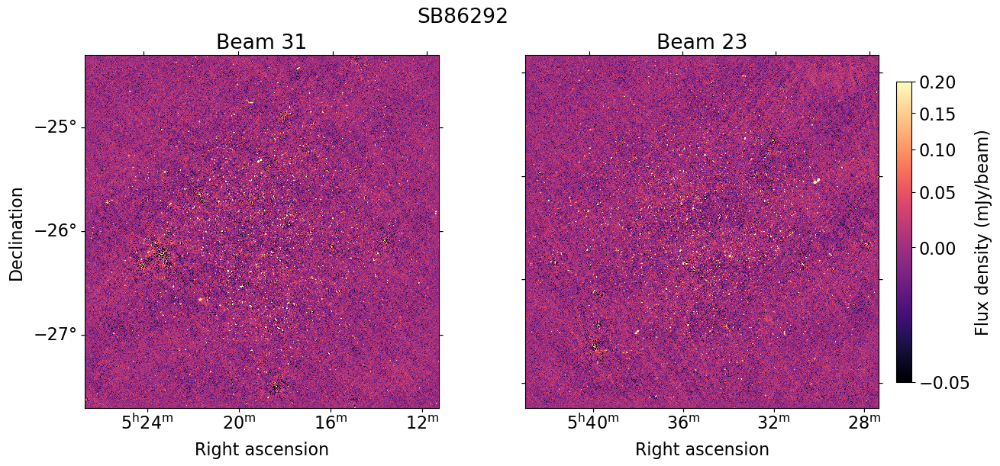

In [401]:
compare_beam_images("86292", beams=(31, 23),vmin=-0.05, vmax=0.2, gamma=0.5)

Saved: /Users/cordun/Documents/Australia/CSIRO/time_dep/plots/61078/SB61078_beam34_beam08_full_after.pdf


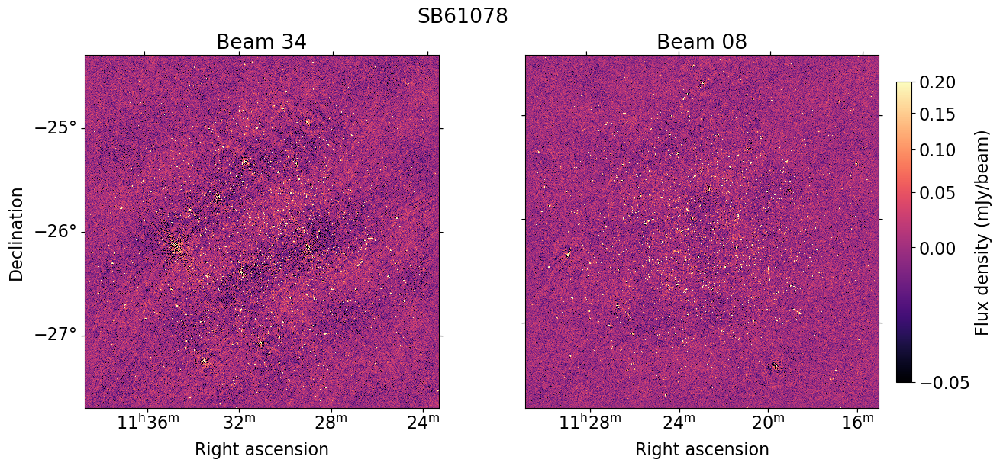

In [402]:
compare_beam_images("61078", beams=(34, 8), vmin=-0.05, vmax=0.2, gamma=0.5)